# 7장. 그래프로 데이터의 이야기를 보여주기


## 제출 정보
- 이름: 유은송
- GitHub ID: song-03
- 작성일: 2026.10.28
- 최종 Notebook URL: https://github.com/song-03/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb
- 분석 범위: 금액 관련 그래프(카테고리별/월별 금액, 상품 가격과 판매 수량, 구매 금액 상위 고객)는 `order_status == "completed"` 주문만 사용했다. 상품 가격 분포는 전체 상품 마스터(100개), 주문 상태별 주문 수는 전체 주문(300건)을 사용했다.
- `total_sales`라는 컬럼명은 공식 코드 이름을 그대로 두었지만, 이 노트북에서는 **completed 주문에 속한 `line_total`(quantity × unit_price) 합계**를 뜻한다. 회계상 순매출과 같은 의미로 단정하지 않는다.

In [1]:
import sys
print(sys.executable)

c:\dev\llm-data-analysis-course\.venv\Scripts\python.exe


## 0. 이 노트북 사용 방법

아래 셀을 위에서부터 차례대로 실행하세요.

- 이 노트북은 5장에서 만든 `data/processed/*_clean.csv` 파일을 사용합니다.
- 전처리 파일이 없다면 먼저 `python scripts/preprocess_data.py`를 실행하세요.
- 그래프 파일은 `reports/figures/` 폴더에 저장합니다.
- 제출용 대표 그래프 3개는 노트북과 같은 위치의 `images/` 폴더에 `graph01.png`~`graph03.png`로도 저장합니다.
- 그래프 해석에서는 관찰과 원인 가설을 반드시 구분합니다.

## 1. 시각화는 분석 질문에서 시작된다

좋은 시각화는 그래프 종류를 많이 아는 데서 시작하지 않습니다. 먼저 어떤 질문에 답하려는지 정해야 합니다.

| 분석 목적 | 적합한 그래프 | 예시 질문 |
|---|---|---|
| 범주별 크기 비교 | 막대그래프 | 카테고리별 매출은 어떻게 다른가? |
| 시간 흐름 확인 | 선 그래프 | 월별 매출은 어떻게 변하는가? |
| 값의 분포 확인 | 히스토그램 | 상품 가격은 어떤 범위에 몰려 있는가? |
| 두 변수 관계 확인 | 산점도 | 가격과 판매 수량은 관계가 있는가? |
| 상위 항목 비교 | 가로 막대그래프 | 구매 금액 상위 고객은 누구인가? |
| 비율 비교 | 막대그래프 또는 파이 차트 | 주문 상태별 비중은 어떻게 되는가? |


## 2. 이번 장에서 만들 그래프

이번 장에서는 6장 EDA에서 만든 질문을 그래프로 표현합니다.

| 시각화 질문 | 사용할 데이터 | 그래프 |
|---|---|---|
| 1. 카테고리별 매출은 어떻게 다른가? | `category_sales` | 막대그래프 |
| 2. 월별 매출은 어떻게 변하는가? | `monthly_sales` | 선 그래프 |
| 3. 상품 가격은 어떤 구간에 몰려 있는가? | `products` | 히스토그램 |
| 4. 상품 가격과 판매 수량은 관계가 있는가? | `product_sales` | 산점도 |
| 5. 구매 금액 상위 고객은 누구인가? | `customer_sales` | 가로 막대그래프 |
| 6. 주문 상태별 주문 수는 어떻게 다른가? | `orders` | 막대그래프 |


## 1. 시각화 질문과 그래프 선택
| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 주문 기준 금액은 어떻게 다른가? | 막대그래프 | 같은 completed 주문 범위에서 카테고리별 금액 규모를 비교하기 좋다. 파이 차트보다 7개 카테고리의 실제 금액 차이와 순서가 한눈에 보인다. |
| 월별 completed 주문 기준 금액은 어떻게 변하는가? | 선그래프 | 2025-07부터 2026-07까지 월별 금액 변화를 시간 순서대로 따라갈 수 있다. 각 월을 따로 보여주는 막대그래프보다 금액이 어느 시점에 늘고 줄었는지 흐름이 잘 드러난다. |
| 상품 가격은 어떤 구간에 몰려 있는가? | 히스토그램 | 가격이 어느 구간에 많이 모여 있는지, 분포의 꼬리가 어떻게 나타나는지, 극단값 후보가 있는지를 한 그래프에서 살필 수 있다. |

1. 질문: 카테고리별 completed 주문 기준 금액은 어떻게 다른가? - 대표 질문
- 분석 대상: completed 주문에 포함된 주문 상세(상품별 주문 데이터)
- 분석 범위: `order_status == "completed"` 주문의 카테고리별 금액
- 사용할 지표: category, total_sales(completed 주문의 line_total 합계)
- 선택한 그래프: 막대그래프
- 선택 이유: 같은 completed 주문 범위에서 카테고리별 금액을 바로 비교할 수 있다. 금액이 큰 카테고리와 작은 카테고리의 순서와 차이도 함께 드러난다.

2. 질문: 월별 completed 주문 기준 금액은 어떻게 변하는가? - 대표 질문
- 분석 대상: completed 주문 데이터
- 분석 범위: 주문일(order_date)이 유효한 completed 주문, 2025-07부터 2026-07까지 월별 금액
- 사용할 지표: order_month, total_sales(completed 주문의 line_total 합계), order_count
- 선택한 그래프: 선그래프
- 선택 이유: 시간 순서에 따라 금액이 어떻게 늘고 줄었는지, 변화가 큰 시점이 언제인지 따라가기 좋다. 전체적인 흐름을 보기에는 막대그래프보다 낫다.

3. 질문: 상품 가격은 어떤 구간에 몰려 있는가? - 대표 질문
- 분석 대상: 전체 상품 데이터(상품 마스터 100개)
- 분석 범위: 상품별 등록 가격 분포(주문 상태와 무관하므로 상태 필터를 적용하지 않음)
- 사용할 지표: price
- 선택한 그래프: 히스토그램
- 선택 이유: 상품 가격을 일정한 구간으로 나누어 각 가격대에 상품이 얼마나 있는지 확인할 수 있다. 상품이 많이 몰린 구간과 상대적으로 적은 구간도 함께 볼 수 있다.

4. 질문: 상품 가격과 completed 판매 수량은 어떤 관계가 있는가?
- 분석 대상: completed 주문에 포함된 상품별 판매 데이터
- 분석 범위: 상품별 가격과 completed 주문 누적 판매 수량(completed 판매 기록이 없는 상품은 점으로 표시되지 않음)
- 사용할 지표: price, total_quantity(completed 판매 수량)
- 선택한 그래프: 산점도
- 선택 이유: 가격과 판매 수량의 관계를 한 번에 볼 수 있다. 값이 많이 모인 구간과 가격 또는 판매 수량이 유독 높은 상품도 함께 볼 수 있다.

5. 질문: completed 주문 기준 구매 금액이 높은 고객은 누구인가?
- 분석 대상: completed 주문의 고객별 구매 데이터
- 분석 범위: completed 주문 누적 구매 금액 상위 10명(이름, 도시 등 개인정보는 사용하지 않고 익명 라벨로 표시)
- 사용할 지표: total_sales, order_count
- 선택한 그래프: 가로 막대그래프
- 선택 이유: 고객별 구매 금액을 큰 순서대로 비교하기 쉽다. 고객 라벨도 세로 막대그래프보다 읽기 편하다.

6. 질문: 주문 상태별 주문 수는 어떻게 다른가?
- 분석 대상: 전체 주문 데이터
- 분석 범위: completed, cancelled, refunded 주문(전체 300건)
- 사용할 지표: order_count
- 선택한 그래프: 막대그래프
- 선택 이유: 상태별 주문 건수를 바로 비교할 수 있다. completed, cancelled, refunded 주문이 각각 어느 정도인지 한눈에 보인다.

## 3. 패키지와 경로 설정

노트북이 `notebooks/` 폴더 안에서 실행되는 경우와 프로젝트 루트에서 실행되는 경우를 모두 고려해 경로를 설정합니다.


In [2]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == 'notebooks':
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'
IMAGE_DIR = CURRENT_DIR / 'images'  # 제출용 대표 그래프(graph01~03.png) 저장 위치

REPORT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('현재 실행 위치:', CURRENT_DIR)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('그래프 저장 폴더:', FIGURE_DIR)
print('제출용 대표 그래프 폴더:', IMAGE_DIR)

현재 실행 위치: c:\dev\llm-data-analysis-course\notebooks
프로젝트 루트: c:\dev\llm-data-analysis-course
전처리 데이터 폴더: c:\dev\llm-data-analysis-course\data\processed
그래프 저장 폴더: c:\dev\llm-data-analysis-course\reports\figures
제출용 대표 그래프 폴더: c:\dev\llm-data-analysis-course\notebooks\images


## 4. 한글 폰트 설정

matplotlib에서 한글 제목이나 축 이름을 사용하면 글자가 깨질 수 있습니다. Windows 환경에서는 보통 `Malgun Gothic`을 사용합니다. Mac은 `AppleGothic`, Linux는 `NanumGothic`을 사용할 수 있습니다.


실행 환경마다 설치된 폰트가 다르므로, 실습 진행 가이드 STEP 4에 나온 공통 함수 `setup_korean_font()`로 설치된 한글 폰트를 자동 선택한다(Windows에서는 `Malgun Gothic`이 먼저 선택된다).

In [3]:
from src.visualization import setup_korean_font

selected_font = setup_korean_font('Malgun Gothic')
print('사용 한글 폰트:', selected_font or '자동 선택 실패 - 설치된 한글 폰트 확인 필요')

사용 한글 폰트: Malgun Gothic


## 5. 전처리 데이터 불러오기

7장은 5장에서 저장한 전처리 데이터를 사용합니다. 파일이 없다면 터미널에서 `python scripts/preprocess_data.py`를 먼저 실행하세요.


In [4]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'products_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    for path in missing_files:
        print('누락 파일:', path)
    raise FileNotFoundError('전처리 파일이 없습니다. 먼저 python scripts/preprocess_data.py 를 실행하세요.')

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('전처리 데이터 불러오기 완료')


전처리 데이터 불러오기 완료


In [5]:
orders['order_date'] = pd.to_datetime(orders['order_date'], errors='coerce')

if 'order_month' not in orders.columns:
    orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)

if 'line_total' not in order_items.columns:
    order_items['line_total'] = order_items['quantity'] * order_items['unit_price']

print('customers:', customers.shape)
print('products:', products.shape)
print('orders:', orders.shape)
print('order_items:', order_items.shape)


customers: (150, 6)
products: (100, 4)
orders: (300, 7)
order_items: (764, 6)


## 6. 시각화를 위한 집계 데이터 만들기

그래프를 그리기 전에 필요한 집계표를 만듭니다. 대부분의 시각화는 원본 데이터를 바로 그리기보다, 질문에 맞게 요약한 표를 만든 뒤 그립니다.


금액 관련 집계는 모두 **completed 주문**만 사용하므로, 집계표를 만들기 전에 completed 범위와 source total을 먼저 고정한다.

In [6]:
# 금액 관련 집계의 공통 범위: completed 주문
print('[전체 주문 상태 분포]')
print(orders['order_status'].value_counts(dropna=False).to_string())

completed_orders = orders.loc[orders['order_status'].eq('completed')].copy()
completed_items = order_items.merge(
    completed_orders[['order_id', 'customer_id', 'order_date', 'order_status']],
    on='order_id',
    how='inner',
)

status_amount = (
    order_items.merge(orders[['order_id', 'order_status']], on='order_id', how='left')
    .groupby('order_status')['line_total'].sum()
)
all_status_total = order_items['line_total'].sum()
completed_source_total = completed_items['line_total'].sum()

print('\n[주문 상태별 line_total 합계]')
print(status_amount.map(lambda v: f'{v:,.0f}원').to_string())
print('\ncompleted 주문 수:', completed_orders['order_id'].nunique())
print('completed 주문 상세 행 수:', len(completed_items))
print('completed_items에 포함된 상태:', sorted(completed_items['order_status'].unique()))
print('전체 상태 line_total 합계:', f'{all_status_total:,.0f}원')
print('completed source total:', f'{completed_source_total:,.0f}원')
print('completed 비중:', f'{completed_source_total / all_status_total * 100:.1f}%')

[전체 주문 상태 분포]
order_status
completed    184
cancelled     64
refunded      52

[주문 상태별 line_total 합계]
order_status
cancelled     62,181,000원
completed    148,990,000원
refunded      44,439,000원

completed 주문 수: 184
completed 주문 상세 행 수: 474
completed_items에 포함된 상태: ['completed']
전체 상태 line_total 합계: 255,610,000원
completed source total: 148,990,000원
completed 비중: 58.3%


In [7]:
# completed 주문 상세에 상품 정보(category, price)를 붙인다.
sales_items = completed_items.merge(
    products,
    on='product_id',
    how='left',
)

print('병합 전 completed_items:', completed_items.shape)
print('병합 후 sales_items:', sales_items.shape)
print('카테고리 누락:', sales_items['category'].isna().sum())

sales_items.head()

병합 전 completed_items: (474, 9)
병합 후 sales_items: (474, 12)
카테고리 누락: 0


,order_item_id,order_id,product_id,quantity,unit_price,line_total,customer_id,order_date,order_status,product_name,category,price
0,1,1,100,3,102000,306000,123,2026-05-07,completed,도서 상품 100,도서,102000
1,2,1,87,5,25000,125000,123,2026-05-07,completed,도서 상품 087,도서,25000
2,3,1,7,3,142000,426000,123,2026-05-07,completed,도서 상품 007,도서,142000
3,4,1,9,3,193000,579000,123,2026-05-07,completed,스포츠 상품 009,스포츠,193000
4,13,6,83,3,24000,72000,87,2026-03-21,completed,전자기기 상품 083,전자기기,24000


In [8]:
category_sales = (
    sales_items
    .groupby('category', as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

category_sales['sales_ratio'] = (
    category_sales['total_sales'] / category_sales['total_sales'].sum() * 100
).round(2)

category_sales


,category,total_quantity,total_sales,sales_ratio
3,스포츠,295,31743000,21.31
5,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
1,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
0,도서,149,16389000,11.00
6,패션,111,10587000,7.11


In [9]:
# completed 주문 상세를 월별로 집계한다.
order_sales = completed_items.copy()

order_sales['order_date'] = pd.to_datetime(order_sales['order_date'], errors='coerce')
print('날짜 변환 실패(NaT) 행 수:', order_sales['order_date'].isna().sum())
order_sales['order_month'] = order_sales['order_date'].dt.to_period('M').astype(str)

monthly_sales = (
    order_sales
    .dropna(subset=['order_date'])
    .groupby('order_month', as_index=False)
    .agg(
        total_sales=('line_total', 'sum'),
        order_count=('order_id', 'nunique'),
    )
    .sort_values('order_month')
)

monthly_sales['avg_order_value'] = (
    monthly_sales['total_sales'] / monthly_sales['order_count']
).round(0)

monthly_sales

날짜 변환 실패(NaT) 행 수: 0


,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


In [10]:
# 월별 그래프를 그리기 전 확인: 첫 달·마지막 달 범위, 누락 월, 실제 0인 월
print('completed 주문일 범위:', order_sales['order_date'].min().date(), '~', order_sales['order_date'].max().date())
print('전체 주문일 범위:', orders['order_date'].min().date(), '~', orders['order_date'].max().date())

full_months = pd.period_range(
    order_sales['order_date'].min(), order_sales['order_date'].max(), freq='M'
).astype(str)
missing_months = sorted(set(full_months) - set(monthly_sales['order_month']))
zero_months = monthly_sales.loc[monthly_sales['total_sales'].eq(0), 'order_month'].tolist()

print('기간 내 전체 월 수:', len(full_months), '/ 집계된 월 수:', len(monthly_sales))
print('데이터가 없는 월(누락):', missing_months if missing_months else '없음')
print('금액이 실제 0인 월:', zero_months if zero_months else '없음')

# 전체 주문 대비 completed 주문 비중(월별)
monthly_status_check = (
    orders.assign(order_month=orders['order_date'].dt.to_period('M').astype(str))
    .groupby('order_month', as_index=False)
    .agg(all_order_count=('order_id', 'nunique'))
    .merge(monthly_sales[['order_month', 'order_count']], on='order_month', how='left')
    .rename(columns={'order_count': 'completed_order_count'})
)
monthly_status_check['completed_ratio_pct'] = (
    monthly_status_check['completed_order_count'] / monthly_status_check['all_order_count'] * 100
).round(1)
monthly_status_check

completed 주문일 범위: 2025-07-09 ~ 2026-07-05
전체 주문일 범위: 2025-07-09 ~ 2026-07-08
기간 내 전체 월 수: 13 / 집계된 월 수: 13
데이터가 없는 월(누락): 없음
금액이 실제 0인 월: 없음


,order_month,all_order_count,completed_order_count,completed_ratio_pct
0,2025-07,15,8,53.3
1,2025-08,24,18,75.0
2,2025-09,23,13,56.5
3,2025-10,39,26,66.7
4,2025-11,23,12,52.2
5,2025-12,26,14,53.8
6,2026-01,29,22,75.9
7,2026-02,29,17,58.6
8,2026-03,21,14,66.7
9,2026-04,31,23,74.2


In [11]:
product_sales = (
    sales_items
    .groupby(['product_id', 'product_name', 'category', 'price'], as_index=False)
    .agg(
        total_quantity=('quantity', 'sum'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

unsold_products = products.loc[~products['product_id'].isin(product_sales['product_id'])]
print('completed 판매 기록이 있는 상품 수:', len(product_sales))
print('completed 판매 기록이 없는 상품 수:', len(unsold_products), '(산점도에 표시되지 않음)')

product_sales.head()

completed 판매 기록이 있는 상품 수: 98
completed 판매 기록이 없는 상품 수: 2 (산점도에 표시되지 않음)


,product_id,product_name,category,price,total_quantity,total_sales
39,41,스포츠 상품 041,스포츠,163000,35,5705000
11,12,식품 상품 012,식품,175000,25,4375000
8,9,스포츠 상품 009,스포츠,193000,20,3860000
70,72,뷰티 상품 072,뷰티,189000,20,3780000
69,71,전자기기 상품 071,전자기기,161000,23,3703000


In [12]:
# 개인정보 노출을 막기 위해 이름(name)·도시(city)는 집계에 사용하지 않고 customer_id만 사용한다.
customer_sales = (
    order_sales
    .groupby('customer_id', as_index=False)
    .agg(
        order_count=('order_id', 'nunique'),
        total_sales=('line_total', 'sum'),
    )
    .sort_values('total_sales', ascending=False)
)

customer_sales['avg_order_value'] = (
    customer_sales['total_sales'] / customer_sales['order_count']
).round(0)

print('집계 컬럼:', customer_sales.columns.tolist())
customer_sales.head()

집계 컬럼: ['customer_id', 'order_count', 'total_sales', 'avg_order_value']


,customer_id,order_count,total_sales,avg_order_value
76,117,5,4100000,820000.0
62,102,4,3996000,999000.0
51,83,4,3880000,970000.0
21,30,5,3590000,718000.0
29,40,4,3523000,880750.0


In [13]:
# 주문 상태 분포는 전체 주문(300건)을 사용한다.
order_status = orders['order_status'].value_counts(dropna=False).reset_index()
order_status.columns = ['order_status', 'order_count']
order_status

,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


## 7. 카테고리별 completed 주문 기준 금액 막대그래프

카테고리별 금액은 범주별 크기 비교이므로 막대그래프가 적합합니다. 그래프는 화면에 표시하고 동시에 PNG 파일로 저장합니다.

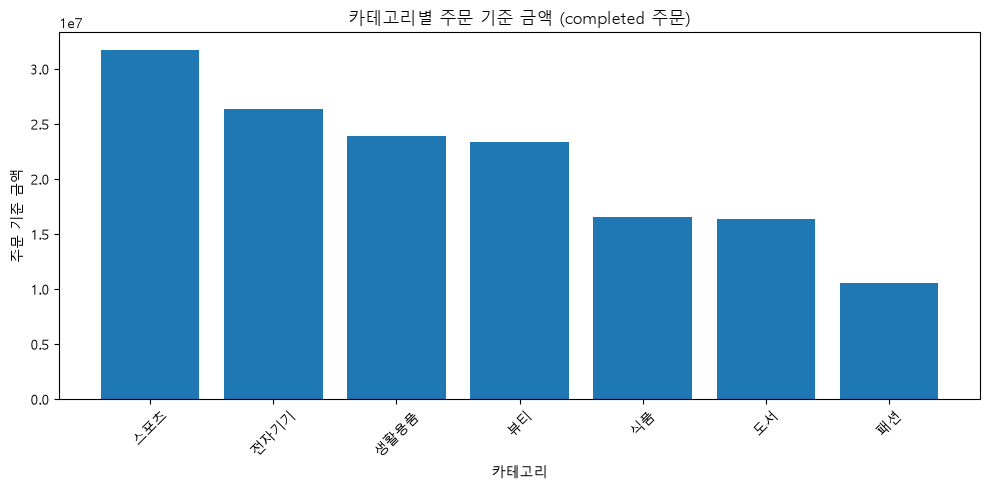

In [14]:
# 처음 그린 기본 막대그래프 (아래 「내가 발견한 시각화 위험」에서 단위 표시를 개선함)
plt.figure(figsize=(10, 5))
plt.bar(category_sales['category'], category_sales['total_sales'])
plt.title('카테고리별 주문 기준 금액 (completed 주문)')
plt.xlabel('카테고리')
plt.ylabel('주문 기준 금액')
plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

해석 예시:

> 관찰: 카테고리별 매출 크기가 서로 다르게 나타납니다.
> 가설: 매출 차이는 판매 수량 또는 평균 단가 차이에서 비롯되었을 수 있습니다.
> 추가 분석: 카테고리별 판매 수량과 평균 단가를 함께 확인해야 합니다.


### 내가 발견한 시각화 위험 또는 개선점

**1) 금액 축 단위 누락**
- 문제: 카테고리별 막대그래프의 금액 축이 `1e7` 형식으로 표시되고 통화와 금액 단위가 표시되지 않았다.
- 왜 오해를 만들 수 있는가: 보는 사람이 숫자의 통화와 단위를 직접 추정해야 한다. 다른 자료와 비교할 때 금액을 잘못 이해할 수도 있다.
- 수정 방법: 원본 데이터에서 통화 단위를 먼저 확인하고 y축 제목과 눈금에 표시한다. 확인되지 않은 통화를 임의로 넣지는 않는다.
- 수정 후 확인 결과: y축에 (백만 원)을 표기하고 눈금을 백만 원 단위로 바꿨다. 각 막대 위에도 금액을 적었고 월별 선그래프에도 같은 방식을 적용했다.

**2) 분석 범위(all status vs completed)**
- 문제: 처음에는 주문 상태를 필터링하지 않은 all status 기준으로 금액 그래프를 그렸다. 이렇게 하면 취소/환불 주문 금액(합계 106,620,000원)이 함께 들어간다.
- 왜 오해를 만들 수 있는가: all status 기준에서는 뷰티가 2위였지만 completed 기준에서는 4위로 내려간다. 범위에 따라 순위와 결론이 달라지는데, 제목에 범위가 없으면 독자는 어떤 기준인지 알 수 없다.
- 수정 방법: 과제 요구사항에 따라 금액 관련 그래프를 모두 completed 주문으로 다시 집계하고, 제목에 `(completed 주문)`을 표시했다.
- 수정 후 확인 결과: completed source total 148,990,000원과 카테고리별/월별 합계가 일치함을 아래 검증 셀에서 확인했다(PASS).

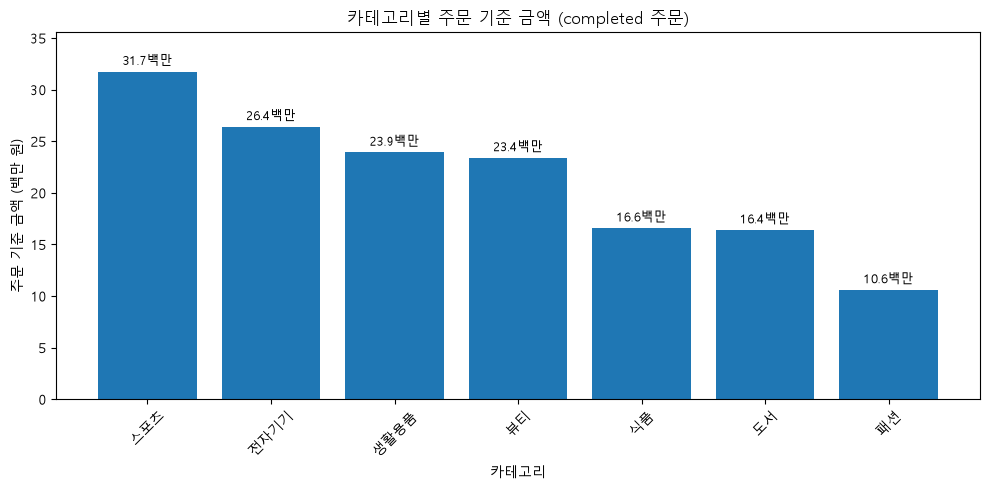

In [15]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    category_sales['category'],
    category_sales['total_sales'],
)
graph1_bars = bars  # 검증 셀에서 막대 높이와 집계값을 비교하기 위해 보관

ax.set_title('카테고리별 주문 기준 금액 (completed 주문)')
ax.set_xlabel('카테고리')
ax.set_ylabel('주문 기준 금액 (백만 원)')
ax.set_ylim(0, category_sales['total_sales'].max() * 1.12)  # 0부터 시작, 위쪽은 라벨 여백

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f'{value / 1_000_000:,.0f}')
)

ax.bar_label(
    bars,
    labels=[
        f'{value / 1_000_000:,.1f}백만'
        for value in category_sales['total_sales']
    ],
    padding=3,
    fontsize=9,
)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / 'ch07_category_sales_bar.png',
    dpi=150,
    bbox_inches='tight',
)
plt.savefig(IMAGE_DIR / 'graph01.png', dpi=150, bbox_inches='tight')

plt.show()

## 2. 대표 그래프 1
![대표 그래프 1](images/graph01.png)

### 원본 집계값
- 데이터 범위: `order_status == "completed"` 주문의 주문 상세(`sales_items`), 금액 = `line_total`(quantity × unit_price) 합계
- completed source total: 148,990,000원 (카테고리별 합계와 일치, 아래 검증 셀 PASS)
- 사용한 집계표: `category_sales['category']`, `category_sales['total_sales']`

| 카테고리 | 판매 수량 | completed 주문 기준 금액 | 비중 |
|---|---:|---:|---:|
| 스포츠 | 295 | 31,743,000원 | 21.31% |
| 전자기기 | 259 | 26,400,000원 | 17.72% |
| 생활용품 | 272 | 23,915,000원 | 16.05% |
| 뷰티 | 223 | 23,383,000원 | 15.69% |
| 식품 | 133 | 16,573,000원 | 11.12% |
| 도서 | 149 | 16,389,000원 | 11.00% |
| 패션 | 111 | 10,587,000원 | 7.11% |
| **합계** | **1,442** | **148,990,000원** | **100.00%** |

### 결과 관찰
x축을 카테고리, y축을 주문 기준 금액(백만 원)으로 하여 막대그래프로 시각화했다(범위: completed 주문). 금액이 큰 순서대로 스포츠, 전자기기, 생활용품, 뷰티, 식품, 도서, 패션이었다. 스포츠가 31,743,000원(21.31%)으로 가장 컸고 패션은 10,587,000원(7.11%)으로 가장 작았다. 두 카테고리의 차이는 21,156,000원이며 스포츠 금액은 패션의 약 3.0배였다. 반면 생활용품(23,915,000원)과 뷰티(23,383,000원)의 차이는 532,000원, 식품(16,573,000원)과 도서(16,389,000원)의 차이는 184,000원으로 매우 작았다. 판매 수량 순서는 스포츠(295), 생활용품(272), 전자기기(259), 뷰티(223), 도서(149), 식품(133), 패션(111)으로 금액 순서와 일부 달랐다. 막대는 금액이 큰 순서대로 정렬했고 값 축은 0부터 시작하도록 설정했다. 처음 그린 그래프는 y축이 `1e7` 형식이라 단위를 읽기 어려웠다. 그래서 백만 원 단위 축과 막대 위 금액 라벨을 추가한 그래프를 대표 그래프로 사용했다.

### 나의 해석과 판단
막대그래프로 그리니 어떤 카테고리의 completed 주문 기준 금액이 크고 작은지 순서가 한눈에 들어왔다. 막대 길이만으로는 정확한 금액과 비중을 읽기 어려워 막대 위에 금액 라벨을 달았고 비중은 집계표로 함께 봤다. 스포츠는 금액과 판매 수량이 모두 가장 높았다. 그렇다고 스포츠가 가장 인기 있거나 고객이 선호하는 품목이라고 단정하지는 않았다. 금액에는 판매 수량과 단가가 함께 반영되기 때문이다. 실제로 생활용품은 전자기기보다 판매 수량이 많지만(272개 vs 259개) 금액은 더 작았고, 도서도 식품보다 판매 수량이 많지만(149개 vs 133개) 금액은 조금 작았다. 따라서 카테고리 간 금액 차이를 수량 차이로 일괄 설명해서는 안 된다. all status 기준으로 그렸을 때는 뷰티가 2위였지만 completed 기준에서는 4위였다. 분석 범위를 어떻게 정하느냐에 따라 순위가 달라질 수 있으니, 금액 그래프는 범위를 제목과 본문에 반드시 밝혀야 한다고 판단했다.

### 업무·분석적 의미
카테고리별 completed 주문 기준 금액을 막대그래프로 비교하면 여러 카테고리의 규모와 순서를 빠르게 확인할 수 있다. MD나 판매 담당자는 이 결과를 보고 어떤 카테고리를 먼저 점검할지 정할 수 있다. 재고, 상품 구성, 프로모션 관련 추가 분석 대상을 고르는 데도 활용할 수 있다. 보고를 받는 사람도 원본 표를 하나씩 확인하지 않고 카테고리별 금액 차이를 바로 볼 수 있다. 다만 생활용품과 뷰티, 식품과 도서처럼 금액 차이가 작은 카테고리는 순위만 보고 우열을 판단하지 않도록 실제 금액 차이를 함께 보고해야 한다.

### 한계와 추가 확인 사항
이번 그래프는 completed 주문만 사용했으므로 취소/환불 주문은 포함되지 않는다(cancelled 62,181,000원, refunded 44,439,000원 제외). `line_total`은 quantity × unit_price로 계산한 주문 상세 금액이며 할인, 배송비, 원가가 반영되지 않았다. 그래서 이 금액을 회계상 순매출이나 수익성으로 보기는 어렵다. 금액 차이만으로는 카테고리별 차이가 왜 생겼는지도 알 수 없다. 판매 수량이 많아서인지, 상품 가격이 높아서인지, 일부 고가 상품의 영향인지 따로 확인해야 한다. 추가로 카테고리별 주문 수, 판매 수량, 평균 판매 단가, 상품 수를 살펴볼 필요가 있다. 카테고리별 취소/환불 비중과 월별 변화도 함께 비교한다.

## 8. 월별 completed 주문 기준 금액 선 그래프

월별 금액은 시간 흐름을 보는 문제이므로 선 그래프가 적합합니다. x축 순서가 월 순서대로 정렬되어 있어야 합니다.

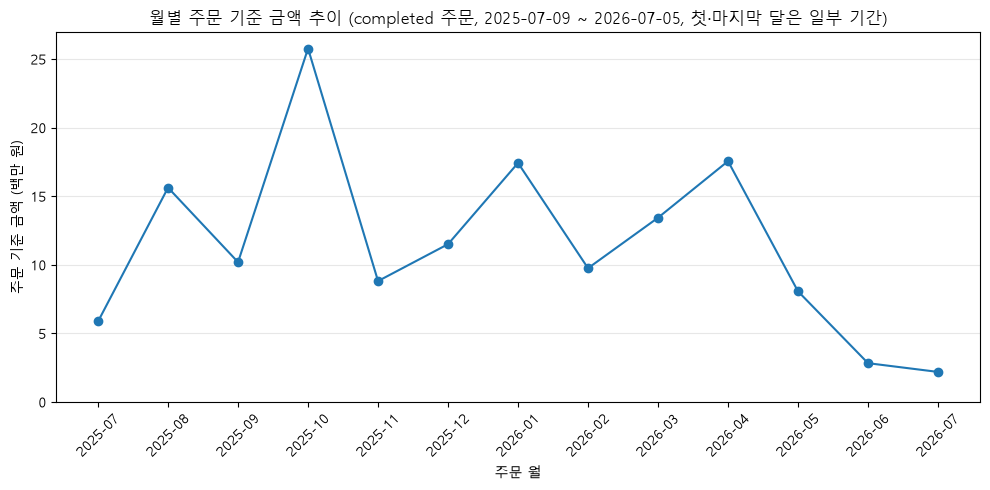

In [16]:
from matplotlib.ticker import FuncFormatter

first_day = order_sales['order_date'].min().date()
last_day = order_sales['order_date'].max().date()

fig, ax = plt.subplots(figsize=(10, 5))
graph2_line, = ax.plot(monthly_sales['order_month'], monthly_sales['total_sales'], marker='o')
ax.set_title(f'월별 주문 기준 금액 추이 (completed 주문, {first_day} ~ {last_day}, 첫·마지막 달은 일부 기간)')
ax.set_xlabel('주문 월')
ax.set_ylabel('주문 기준 금액 (백만 원)')
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f'{value / 1_000_000:,.0f}')
)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_monthly_sales_line.png', dpi=150, bbox_inches='tight')
plt.savefig(IMAGE_DIR / 'graph02.png', dpi=150, bbox_inches='tight')
plt.show()

월별 매출이 증가하거나 감소해도 그 원인을 바로 단정하면 안 됩니다. 주문 수, 평균 주문 금액, 프로모션 여부, 특정 카테고리 매출 변화를 추가로 확인해야 합니다.


## 3. 대표 그래프 2
![대표 그래프 2](images/graph02.png)

### 원본 집계값
- 데이터 범위: 주문일이 유효한 completed 주문(날짜 변환 실패 0행), 금액 = `line_total` 합계
- 월별 합계: 148,990,000원 (completed source total과 일치, 아래 검증 셀 PASS)
- 주문일 범위: completed 주문 2025-07-09 ~ 2026-07-05 (전체 주문 데이터는 2025-07-09 ~ 2026-07-08) → 첫 달(2025-07)과 마지막 달(2026-07)은 한 달 전체가 아님
- 사용한 집계표: `monthly_sales`, `monthly_status_check`

| 주문 월 | 주문 기준 금액 | completed 주문 수 | 평균 주문 금액 | 전체 주문 수 | completed 비중 |
|---|---:|---:|---:|---:|---:|
| 2025-07 | 5,869,000원 | 8 | 733,625원 | 15 | 53.3% |
| 2025-08 | 15,621,000원 | 18 | 867,833원 | 24 | 75.0% |
| 2025-09 | 10,190,000원 | 13 | 783,846원 | 23 | 56.5% |
| 2025-10 | 25,766,000원 | 26 | 991,000원 | 39 | 66.7% |
| 2025-11 | 8,812,000원 | 12 | 734,333원 | 23 | 52.2% |
| 2025-12 | 11,501,000원 | 14 | 821,500원 | 26 | 53.8% |
| 2026-01 | 17,423,000원 | 22 | 791,955원 | 29 | 75.9% |
| 2026-02 | 9,749,000원 | 17 | 573,471원 | 29 | 58.6% |
| 2026-03 | 13,429,000원 | 14 | 959,214원 | 21 | 66.7% |
| 2026-04 | 17,553,000원 | 23 | 763,174원 | 31 | 74.2% |
| 2026-05 | 8,063,000원 | 11 | 733,000원 | 20 | 55.0% |
| 2026-06 | 2,826,000원 | 4 | 706,500원 | 16 | 25.0% |
| 2026-07 | 2,188,000원 | 2 | 1,094,000원 | 4 | 50.0% |

### 결과 관찰
x축을 주문 월, y축을 주문 기준 금액(백만 원)으로 하여 꺾은선 그래프로 시각화했다(범위: completed 주문). 기간 내 13개월이 모두 집계되어 중간에 빠진 월은 없었고, 금액이 실제 0인 월도 없었다. 날짜 변환 실패는 0행이었고 월 순서도 시간순으로 올바르게 정렬되었다. 월 금액이 가장 높았던 것은 2025년 10월 25,766,000원(completed 주문 26건)이었고, 가장 낮았던 것은 2026년 7월 2,188,000원(2건)이었다. 그 사이 월들은 약 8백만~17백만 원 범위에서 오르내림을 반복했다(예: 2025-11 8,812,000원 → 2026-01 17,423,000원 → 2026-02 9,749,000원 → 2026-04 17,553,000원). 2026년 5월부터는 8,063,000원 → 2,826,000원 → 2,188,000원으로 낮아졌다. 전체적으로는 지속적인 증가나 감소보다 월별 등락이 크게 나타났다. y축은 0부터 시작하게 설정했다.

### 나의 해석과 판단
꺾은선 그래프로 월별 추이를 그리니 월별 변화와 피크 시점이 한눈에 보였다. 2025년 10월은 completed 주문 수(26건)가 가장 많았고 평균 주문 금액(991,000원)도 높은 편이어서 주문 수와 주문당 금액이 함께 높았던 달이었다. 반면 2026년 2월은 주문 수가 17건으로 적지 않았지만 평균 주문 금액이 573,471원으로 가장 낮았다. 이 달에는 금액이 낮아진 것이 주문 수보다 주문당 금액 차이와 함께 나타났다. 다만 함께 나타난 패턴일 뿐 원인이라고 단정하지는 않았다. 2025년 7월과 2026년 7월이 낮은 것은 데이터 자체가 2025-07-09부터 2026-07-08까지만 있어(completed 주문은 2026-07-05까지) 두 달 모두 한 달 전체를 반영하지 않았기 때문일 가능성이 높다. 2026년 6월은 전체 주문 16건 중 completed가 4건(25.0%)으로, 다른 달(약 52~76%)보다 completed 비중이 크게 낮았다. 이 달의 낮은 금액이 주문 자체가 줄어서인지, 취소/환불이 늘어서인지, 아직 상태가 확정되지 않은 주문 때문인지는 추가 확인이 필요하다고 판단했다. all status 기준에서 보였던 완만한 증가 흐름이 completed 기준에서는 나타나지 않았으니, 추세 해석도 범위에 따라 달라진다. 결과가 약 1년치뿐이므로 월별 추이의 일반적인 경향성(계절성 등)을 말하려면 최소 2개년 이상의 데이터가 필요하다.

### 업무·분석적 의미
꺾은선 그래프를 사용하면 월별 completed 주문 기준 금액이 시간에 따라 어떻게 변했는지 확인할 수 있다. 어느 달의 금액이 높은지만이 아니라 증가하거나 감소한 시점, 변화 폭이 큰 달도 찾을 수 있다. 예를 들어 2025년 10월처럼 금액이 크게 높은 달이나 2026년 2월, 6월처럼 낮은 달은 주문 수, 평균 주문 금액, 카테고리 구성, 주문 상태 비중을 추가로 확인할 대상으로 볼 수 있다. 업무에서는 월별 실적 변화를 확인하고 이후 분석이 필요한 시점을 정하는 데 활용할 수 있다. 주문 금액과 주문 수를 함께 비교하면 두 지표가 비슷하게 움직이는지도 볼 수 있다.

### 한계와 추가 확인 사항
선 그래프는 시간에 따른 변화를 보여줄 뿐 변화가 생긴 원인까지 설명하지는 않는다. 프로모션, 재고, 상품 구성, 판매 기간, 계절성에 대한 정보는 현재 집계에 없으므로 원인으로 판단할 수 없다. 첫 달(2025-07-09부터)과 마지막 달(전체 데이터 2026-07-08까지, completed 주문은 07-05까지)은 일부 기간만 포함하므로 다른 달과 금액을 그대로 비교하면 감소로 오해할 수 있다. 일 평균 금액으로 환산하거나 완전한 월만 비교하는 추가 확인이 필요하다. 2026년 6월의 completed 비중이 왜 낮았는지는 주문 상태별 월별 건수와 상태 변경 시점 정보로 따져 봐야 한다.

## 9. 상품 가격 분포 히스토그램

히스토그램은 숫자형 데이터가 어느 구간에 많이 몰려 있는지 보여줍니다. 상품 가격 분포를 보면 저가/중가/고가 상품이 어떻게 분포하는지 확인할 수 있습니다.


In [17]:
import numpy as np

# 히스토그램 원본 집계값: 전체 상품 마스터 가격 (주문 상태와 무관하므로 상태 필터 없음)
print('[상품 가격 요약 통계]')
print(products['price'].describe().to_string())
print('가장 낮은 가격 5개:', sorted(products['price'])[:5])
print('가장 높은 가격 5개:', sorted(products['price'])[-5:])

q3_counts, q3_edges = np.histogram(products['price'], bins=20)

q3_histogram_table = pd.DataFrame({
    '가격 구간 시작': q3_edges[:-1],
    '가격 구간 끝': q3_edges[1:],
    '상품 수': q3_counts,
})
q3_histogram_table

[상품 가격 요약 통계]
count       100.000000
mean     110040.000000
std       56433.910574
min        5000.000000
25%       65750.000000
50%      112000.000000
75%      161000.000000
max      200000.000000
가장 낮은 가격 5개: [5000, 5000, 10000, 11000, 20000]
가장 높은 가격 5개: [196000, 197000, 197000, 198000, 200000]


,가격 구간 시작,가격 구간 끝,상품 수
0,5000.0,14750.0,4
1,14750.0,24500.0,3
2,24500.0,34250.0,4
3,34250.0,44000.0,6
4,44000.0,53750.0,3
5,53750.0,63500.0,5
6,63500.0,73250.0,4
7,73250.0,83000.0,8
8,83000.0,92750.0,3
9,92750.0,102500.0,2


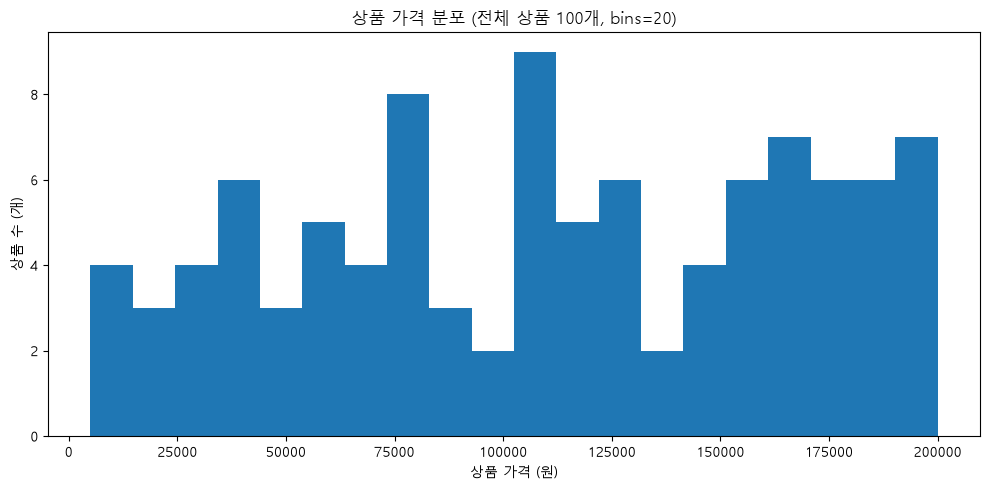

In [18]:
plt.figure(figsize=(10, 5))
plt.hist(products['price'], bins=20)
plt.title(f'상품 가격 분포 (전체 상품 {len(products)}개, bins=20)')
plt.xlabel('상품 가격 (원)')
plt.ylabel('상품 수 (개)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_product_price_hist.png', dpi=150, bbox_inches='tight')
plt.show()

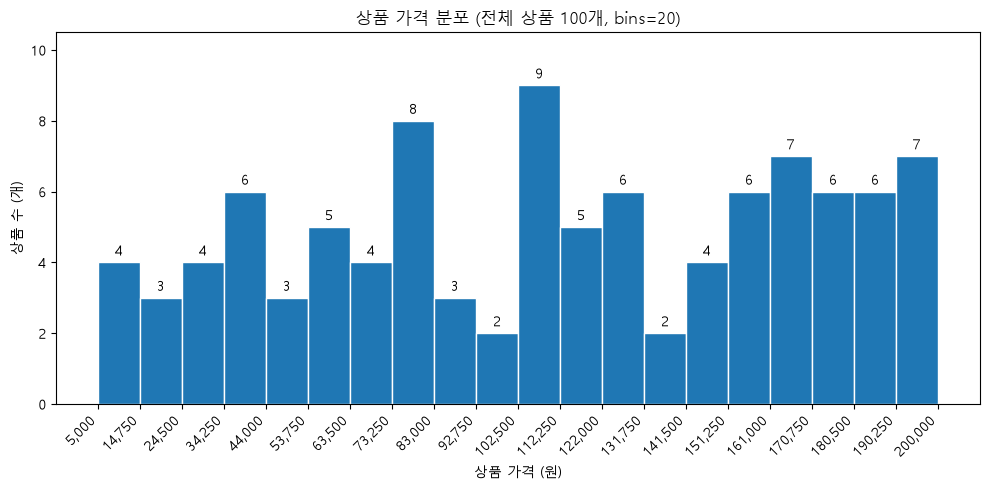

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))

counts, bin_edges, bars = ax.hist(
    products['price'],
    bins=20,
    edgecolor='white',
)
graph3_counts = counts  # 검증 셀에서 원본 구간표와 비교하기 위해 보관

# 각 막대 위에 y값(상품 수) 표시
ax.bar_label(
    bars,
    labels=[str(int(count)) for count in counts],
    padding=3,
)

# bins=20의 모든 가격 구간 경계값을 x축에 표시
ax.set_xticks(bin_edges)
ax.set_xticklabels(
    [f'{price:,.0f}' for price in bin_edges],
    rotation=45,
    ha='right',
)

ax.set_title(f'상품 가격 분포 (전체 상품 {len(products)}개, bins=20)')
ax.set_xlabel('상품 가격 (원)')
ax.set_ylabel('상품 수 (개)')
ax.set_ylim(0, counts.max() + 1.5)  # 막대 위 숫자가 잘리지 않도록 여백 추가

plt.tight_layout()
plt.savefig(IMAGE_DIR / 'graph03.png', dpi=150, bbox_inches='tight')
plt.show()

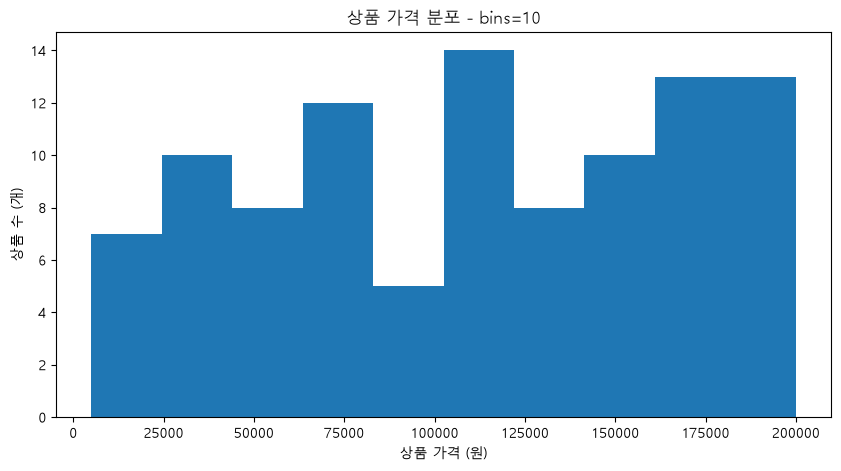

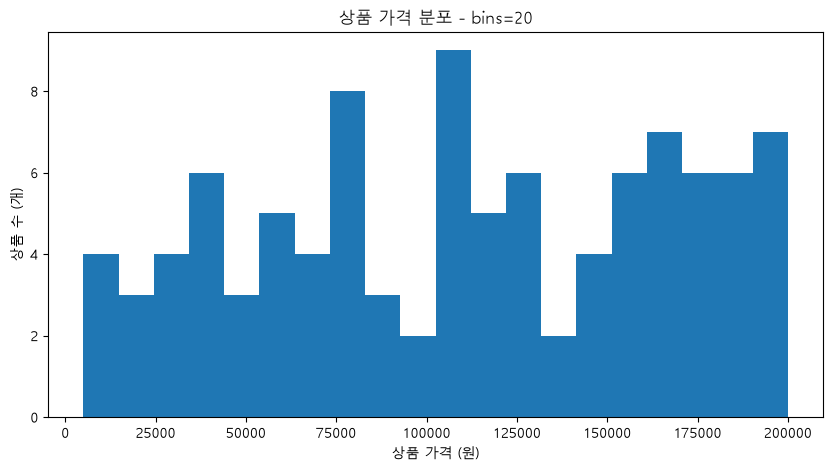

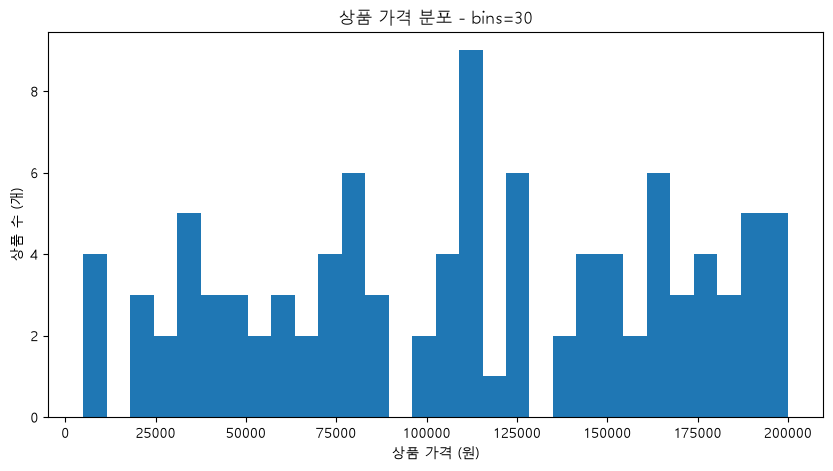

In [20]:
# bins 값을 바꿔도 큰 분포 패턴이 유지되는지 비교
for bins in [10, 20, 30]:

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.hist(products["price"], bins=bins)

    ax.set_title(f"상품 가격 분포 - bins={bins}")
    ax.set_xlabel("상품 가격 (원)")
    ax.set_ylabel("상품 수 (개)")

    plt.show()

## 4. 대표 그래프 3
![대표 그래프 3](images/graph03.png)

### 원본 집계값
- 데이터 범위: 전체 상품 마스터 100개의 등록 가격(`products['price']`). 주문 상태와 무관하므로 상태 필터를 적용하지 않음
- 요약 통계: 최소 5,000원 / 1사분위 65,750원 / 중앙값 112,000원 / 평균 110,040원 / 3사분위 161,000원 / 최대 200,000원
- 가장 낮은 가격 5개: 5,000원, 5,000원, 10,000원, 11,000원, 20,000원
- 가장 높은 가격 5개: 196,000원, 197,000원, 197,000원, 198,000원, 200,000원
- 구간별 상품 수(bins=20, 구간 폭 9,750원), 합계 100개 = 전체 상품 수(아래 검증 셀 PASS)

| 가격 구간(원) | 상품 수 | 가격 구간(원) | 상품 수 |
|---|---:|---|---:|
| 5,000 ~ 14,750 | 4 | 102,500 ~ 112,250 | 9 |
| 14,750 ~ 24,500 | 3 | 112,250 ~ 122,000 | 5 |
| 24,500 ~ 34,250 | 4 | 122,000 ~ 131,750 | 6 |
| 34,250 ~ 44,000 | 6 | 131,750 ~ 141,500 | 2 |
| 44,000 ~ 53,750 | 3 | 141,500 ~ 151,250 | 4 |
| 53,750 ~ 63,500 | 5 | 151,250 ~ 161,000 | 6 |
| 63,500 ~ 73,250 | 4 | 161,000 ~ 170,750 | 7 |
| 73,250 ~ 83,000 | 8 | 170,750 ~ 180,500 | 6 |
| 83,000 ~ 92,750 | 3 | 180,500 ~ 190,250 | 6 |
| 92,750 ~ 102,500 | 2 | 190,250 ~ 200,000 | 7 |

### 결과 관찰
x축을 상품 가격(원), y축을 상품 수(개)로 하여 히스토그램으로 시각화했다. 가격은 5,000원~200,000원 범위에 분포했다. 102,500~112,250원 구간이 9개로 가장 많았고 92,750~102,500원과 131,750~141,500원 구간이 2개로 가장 적었다. 151,250원 이상 구간(5개 구간)에는 합계 32개 상품이 있었다. 중앙값(112,000원)과 평균(110,040원)은 거의 같았다. bins를 10, 20, 30으로 바꿔 가며 히스토그램을 그려 봐도 전체적인 분포 경향성은 유지되었다. 한쪽으로 길게 늘어진 꼬리는 나타나지 않았다.

### 나의 해석과 판단
상품 가격은 특정 한 구간에 몰려 있기보다 낮은 가격부터 높은 가격까지 비교적 넓게 퍼진 형태라고 판단했다. 중앙값과 평균이 거의 같다는 점도 분포가 한쪽으로 치우치지 않았다는 근거가 된다. 10만 원대 초반과 15만 원 이상 구간에 상품이 비교적 많이 분포해, 고가 상품이 일부만 존재하는 구성도 아니었다. 반면 9만 원대~10만 원대 초반, 13만 원대~14만 원대 초반은 주변 구간보다 상품 수가 적었다. 이 차이가 가격 정책 때문인지 카테고리별 가격 차이 때문인지는 현재 그래프만으로 알 수 없다. 극단값 후보는 가격 기준으로 살폈다. 최저 가격 5,000원(2개) 바로 위에는 10,000원, 11,000원 상품이, 최고 가격 200,000원 아래에는 196,000~198,000원 상품이 이어져 있어 다른 값들과 홀로 떨어진 값이 아니었다. 그래서 분포상 극단값 후보로 보지는 않았다. 다만 5,000원은 중앙값의 약 4.5% 수준으로 낮으므로, 실제 판매 가격이 맞는지 상품 마스터에서 한 번 확인해 두면 좋겠다(이상해 보여도 자동 삭제하지 않는다는 5장 원칙 적용).

### 업무·분석적 의미
히스토그램을 보면 상품이 어느 가격대에 많이 분포하는지, 어느 구간에 상품 수가 적은지 쉽게 보인다. 상품 기획이나 MD 업무에서는 현재 상품의 가격 구성을 살펴보는 기초 자료로 쓸 수 있다. 상품 수가 적은 가격대는 판매 수량이나 카테고리 구성을 추가로 확인할 대상으로 볼 수 있다. 상품 수가 많은 구간도 실제 판매가 함께 많은지는 따로 봐야 한다. bins 값을 바꿔 보며 전체적인 분포가 비슷하게 나타나는지도 점검할 수 있다.

### 한계와 추가 확인 사항
이 그래프는 상품 가격과 각 가격 구간의 상품 수만 보여 줄 뿐, 가격대별 판매 수량이나 주문 금액은 알려 주지 않는다. 그러니 상품이 많이 등록된 가격대가 실제로 많이 판매되었거나 금액이 높았다고 판단할 수는 없다. 가격대별 completed 판매 수량과 주문 금액은 이후 따로 집계해 확인할 필요가 있다. 가격 구간도 bins=20 설정에 따라 정해지므로 bins를 바꾸면 가장 많거나 적게 보이는 구간이 달라질 수 있다.

In [21]:
# Q1. 카테고리별 completed 주문 기준 금액 막대그래프 검증
q1_category_total = category_sales['total_sales'].sum()
q1_bar_heights = [bar.get_height() for bar in graph1_bars]

print('[Q1] 카테고리별 completed 주문 기준 금액')
print('completed source total:', f'{completed_source_total:,.0f}원')
print('카테고리별 total_sales 합계:', f'{q1_category_total:,.0f}원')
print('합계 일치:', 'PASS' if completed_source_total == q1_category_total else 'CHECK')
print('막대 높이 = 집계표 값:', 'PASS' if q1_bar_heights == category_sales['total_sales'].tolist() else 'CHECK')
print('금액 내림차순 정렬:', 'PASS' if category_sales['total_sales'].is_monotonic_decreasing else 'CHECK')
print('데이터 범위(completed만):', 'PASS' if set(sales_items['order_status']) == {'completed'} else 'CHECK')
print(category_sales[['category', 'total_sales']].to_string(index=False))


# Q2. 월별 completed 주문 기준 금액 꺾은선그래프 검증
q2_base = order_sales.dropna(subset=['order_date'])
q2_source_total = q2_base['line_total'].sum()
q2_monthly_total = monthly_sales['total_sales'].sum()
q2_month_order = monthly_sales['order_month'].tolist()

print('\n[Q2] 월별 completed 주문 기준 금액')
print('유효한 주문일 기준 completed line_total 합계:', f'{q2_source_total:,.0f}원')
print('월별 total_sales 합계:', f'{q2_monthly_total:,.0f}원')
print('합계 일치:', 'PASS' if q2_source_total == q2_monthly_total else 'CHECK')
print('completed source total과 일치:', 'PASS' if q2_monthly_total == completed_source_total else 'CHECK')
print('월 순서 오름차순:', 'PASS' if q2_month_order == sorted(q2_month_order) else 'CHECK')
print('선그래프 x축 = 집계표 월 순서:', 'PASS' if list(graph2_line.get_xdata()) == q2_month_order else 'CHECK')
print('선그래프 y값 = 집계표 값:', 'PASS' if list(graph2_line.get_ydata()) == monthly_sales['total_sales'].tolist() else 'CHECK')
print('누락 월:', missing_months if missing_months else '없음 (PASS)')
print(monthly_sales[['order_month', 'total_sales', 'order_count']].to_string(index=False))


# Q3. 상품 가격 히스토그램 검증 (원본 구간표 q3_histogram_table은 그래프 전에 만들었음)
print('\n[Q3] 상품 가격 히스토그램')
print('상품 수:', len(products))
print('히스토그램 막대 상품 수 합계:', int(graph3_counts.sum()))
print('상품 수 일치:', 'PASS' if len(products) == graph3_counts.sum() else 'CHECK')
print('그래프 막대 = 원본 구간표:', 'PASS' if (graph3_counts == q3_histogram_table['상품 수'].to_numpy()).all() else 'CHECK')
print(q3_histogram_table.to_string(index=False))

[Q1] 카테고리별 completed 주문 기준 금액
completed source total: 148,990,000원
카테고리별 total_sales 합계: 148,990,000원
합계 일치: PASS
막대 높이 = 집계표 값: PASS
금액 내림차순 정렬: PASS
데이터 범위(completed만): PASS
category  total_sales
     스포츠     31743000
    전자기기     26400000
    생활용품     23915000
      뷰티     23383000
      식품     16573000
      도서     16389000
      패션     10587000

[Q2] 월별 completed 주문 기준 금액
유효한 주문일 기준 completed line_total 합계: 148,990,000원
월별 total_sales 합계: 148,990,000원
합계 일치: PASS
completed source total과 일치: PASS
월 순서 오름차순: PASS
선그래프 x축 = 집계표 월 순서: PASS
선그래프 y값 = 집계표 값: PASS
누락 월: 없음 (PASS)
order_month  total_sales  order_count
    2025-07      5869000            8
    2025-08     15621000           18
    2025-09     10190000           13
    2025-10     25766000           26
    2025-11      8812000           12
    2025-12     11501000           14
    2026-01     17423000           22
    2026-02      9749000           17
    2026-03     13429000           14
    2026-04     17553000           

## 5. 그래프 정확성 점검

### 그래프 정확성 검증
**대표 그래프 1 — 카테고리별 completed 주문 기준 금액 막대그래프**
- 원본 집계값: completed source total 148,990,000원 / 카테고리별 합계 148,990,000원
- 그래프 값과 일치 여부: PASS (막대 높이 7개 = `category_sales['total_sales']`)
- 데이터 범위 일치 여부: PASS (`sales_items`에 completed 상태만 포함)
- 발견한 문제: ① 처음에는 주문 상태 필터 없이(all status) 집계해 취소/환불 금액 106,620,000원이 포함되어 있었다. ② y축이 `1e7` 형식이고 금액 단위가 없었다. ③ 제목과 축에 회계상 의미로 오해될 수 있는 '매출'을 사용했다.
- 수정 내용: completed 주문으로 다시 집계했다. y축을 백만 원 단위로 바꾸고 막대 위에 금액을 표시했다. 제목과 축을 '주문 기준 금액 (completed 주문)'으로 바꿨고 `ylim` 0 시작을 명시했다.

**대표 그래프 2 — 월별 completed 주문 기준 금액 선그래프**
- 원본 집계값: 유효한 주문일 기준 completed 합계 148,990,000원 / 월별 합계 148,990,000원
- 그래프 값과 일치 여부: PASS (x축 월 순서와 y값 13개 = `monthly_sales`)
- 데이터 범위 일치 여부: PASS (completed + 날짜 변환 실패 0행)
- 발견한 문제: ① all status 기준이었다. ② y축 단위가 없었다. ③ 첫 달과 마지막 달이 일부 기간이라는 점이 그래프에 드러나지 않았다.
- 수정 내용: completed로 다시 집계했다. y축을 백만 원 단위로 바꾸고 0부터 시작하게 했다. 제목에 실제 주문일 범위와 '첫/마지막 달은 일부 기간'을 표시했다. 누락 월/0인 월 확인 셀을 추가했다.

**대표 그래프 3 — 상품 가격 히스토그램**
- 원본 집계값: 전체 상품 100개, bins=20 구간별 상품 수 합계 100개
- 그래프 값과 일치 여부: PASS (막대 20개 = `np.histogram` 구간표)
- 데이터 범위 일치 여부: PASS (상품 마스터 전체, 상태 필터 불필요)
- 발견한 문제: ① 제목에 상품 데이터와 관계없는 `(all=status)`가 오타로 들어가 있었다. ② 가격 축 단위가 없었다. ③ 해석의 '원본 집계값'에 산점도용 상위 상품 표가 잘못 들어가 있었다. ④ 구간표를 그래프보다 뒤에서 만들었다.
- 수정 내용: 제목을 '상품 가격 분포 (전체 상품 100개, bins=20)'로, 축을 '(원)', '(개)'로 바꿨다. 원본 집계값을 요약 통계와 구간표로 교체하고, 구간표 셀을 그래프 앞으로 옮겼다.

### 오해를 줄이는 그래프 점검 (실습 진행 가이드 STEP 11 / 과제 요구사항 4)
| 점검 항목 | 결과 | 근거 |
|---|---|---|
| 축이 불필요하게 잘리지 않았다 | ✅ | 막대그래프와 선그래프 모두 값 축 0부터 시작 |
| 숫자 단위를 알 수 있다 | ✅ | 금액 축 (백만 원), 가격 축 (원), 상품 수 (개) |
| 범주 정렬 순서가 적절하다 | ✅ | 카테고리 막대는 금액 내림차순(검증 PASS) |
| 시간 축이 실제 순서로 정렬되어 있다 | ✅ | 월 오름차순(검증 PASS) |
| 데이터가 없는 기간과 실제 0을 구분했다 | ✅ | 기간 내 13개월 모두 존재, 누락 월 없음, 금액 0인 월 없음 |
| 범례가 필요한 그래프에는 범례가 있다 | ✅ | 대표 그래프 3개 모두 단일 계열이라 범례 불필요 |
| 색상만으로 의미를 구분하지 않는다 | ✅ | 단일 색상 사용, 의미 구분은 축과 라벨로 표시 |
| 제목이 실제 분석 범위를 설명한다 | ✅ | 제목에 (completed 주문), 기간, 상품 수 표시 |
| 표본 범위나 기간 차이를 해석에 반영했다 | ✅ | 첫/마지막 부분 월, 2026-06 completed 비중 25.0%를 해석에 반영 |
| 개인정보가 노출되지 않는다 | ✅ | 고객 집계에서 이름과 도시 제외, 상위 고객 그래프는 `Customer + ID` 익명 라벨 |

## 10. 상품 가격과 판매 수량 산점도

산점도는 두 숫자형 변수의 관계를 탐색할 때 사용합니다. 여기서는 상품 가격과 총 판매 수량 사이의 관계를 확인합니다. 산점도만으로 원인 관계를 단정해서는 안 됩니다.


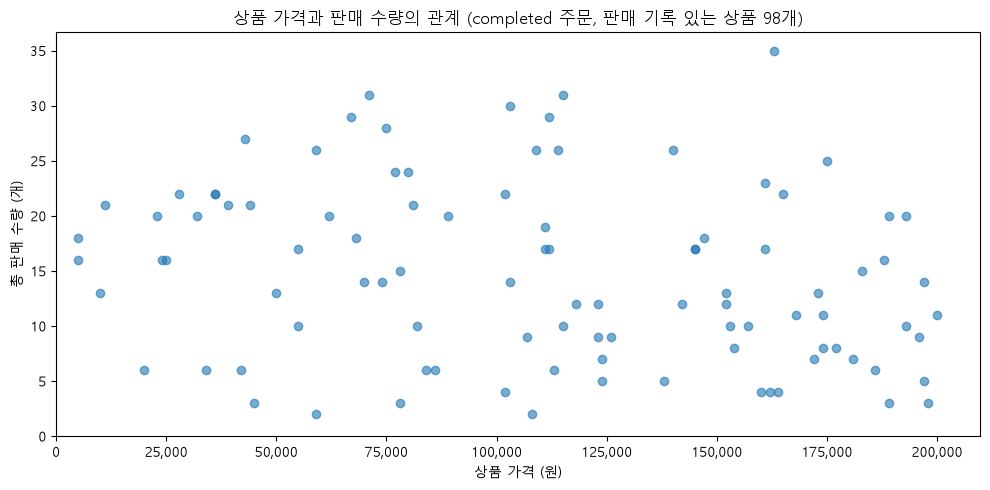

In [22]:
plt.figure(figsize=(10, 5))
plt.scatter(product_sales['price'], product_sales['total_quantity'], alpha=0.6)
plt.title(f'상품 가격과 판매 수량의 관계 (completed 주문, 판매 기록 있는 상품 {len(product_sales)}개)')
plt.xlabel('상품 가격 (원)')
plt.ylabel('총 판매 수량 (개)')
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_price_quantity_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. 구매 금액 상위 고객 가로 막대그래프

상위 항목을 비교할 때는 가로 막대그래프가 읽기 좋습니다. 고객명은 개인정보가 될 수 있으므로 보고서에서는 익명화 라벨을 사용하는 것이 좋습니다.


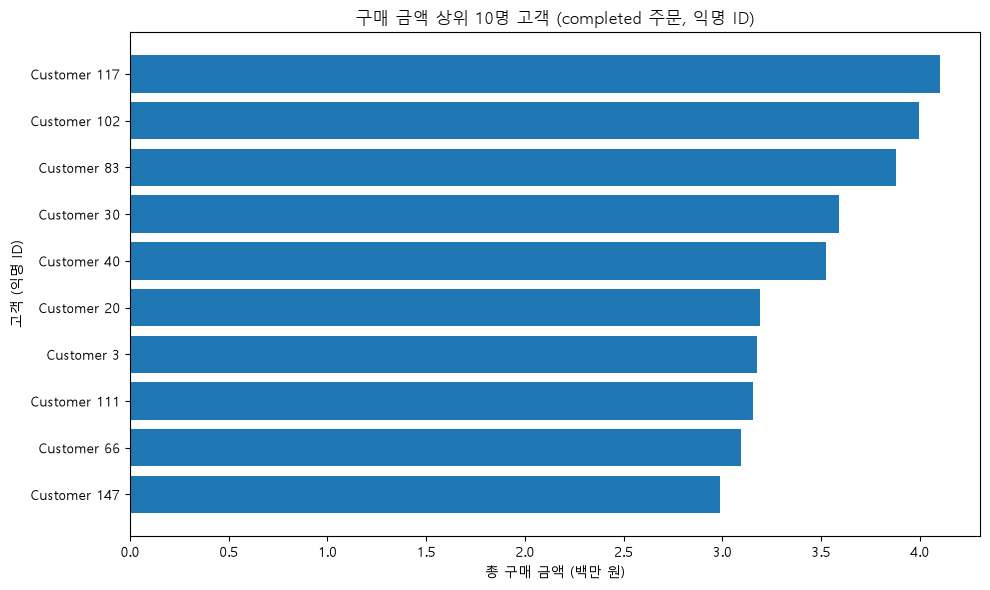

In [23]:
top_customers = customer_sales.head(10).copy()
top_customers['customer_label'] = 'Customer ' + top_customers['customer_id'].astype(str)
top_customers = top_customers.sort_values('total_sales')

plt.figure(figsize=(10, 6))
plt.barh(top_customers['customer_label'], top_customers['total_sales'])
plt.title('구매 금액 상위 10명 고객 (completed 주문, 익명 ID)')
plt.xlabel('총 구매 금액 (백만 원)')
plt.ylabel('고객 (익명 ID)')
plt.xlim(left=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1_000_000:,.1f}'))
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_top_customers_barh.png', dpi=150, bbox_inches='tight')
plt.show()

고객별 구매 금액 상위 그래프는 우수 고객 후보를 확인하는 데 유용합니다. 하지만 한 번에 많이 구매한 고객과 여러 번 반복 구매한 고객은 구분해서 해석해야 합니다.


## 12. 주문 상태별 주문 수 막대그래프

주문 상태별 주문 수는 완료, 취소, 환불 등 주문 상태의 분포를 확인하는 데 사용합니다.


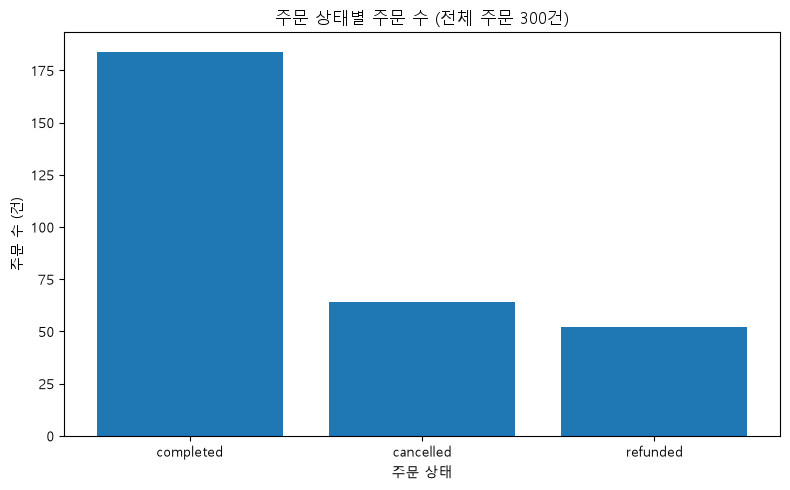

In [24]:
plt.figure(figsize=(8, 5))
plt.bar(order_status['order_status'], order_status['order_count'])
plt.title(f'주문 상태별 주문 수 (전체 주문 {len(orders)}건)')
plt.xlabel('주문 상태')
plt.ylabel('주문 수 (건)')
plt.ylim(bottom=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_order_status_bar.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. 저장된 그래프 확인하기

생성된 그래프 파일을 확인합니다. 보고서나 발표 자료에 사용할 수 있도록 `reports/figures` 폴더에 저장했습니다.


In [25]:
print('[reports/figures]')
for path in sorted(FIGURE_DIR.glob('ch07_*.png')):
    print('-', path.name)

print('\n[제출용 images/]')
for path in sorted(IMAGE_DIR.glob('graph*.png')):
    print('-', path.name, f'({path.stat().st_size:,} bytes)')

[reports/figures]
- ch07_assignment_category_quantity.png
- ch07_assignment_payment_method_count.png
- ch07_category_completed_amount_bar.png
- ch07_category_sales_bar.png
- ch07_customer_order_count_sales_scatter.png
- ch07_monthly_completed_amount_line.png
- ch07_monthly_sales_line.png
- ch07_order_status_bar.png
- ch07_price_completed_quantity_scatter.png
- ch07_price_quantity_scatter.png
- ch07_product_price_hist.png
- ch07_task1_category_quantity_bar.png
- ch07_task4_monthly_order_count_line.png
- ch07_top_customers_anonymized_barh.png
- ch07_top_customers_barh.png

[제출용 images/]
- graph01.png (38,541 bytes)
- graph02.png (74,282 bytes)
- graph03.png (45,718 bytes)


## 14. 시각화 요약표 만들기

각 그래프의 목적과 해석 포인트를 표로 정리하면 이후 보고서 작성이 쉬워집니다.


In [26]:
visualization_summary = pd.DataFrame({
    'chart': [
        '카테고리별 completed 주문 기준 금액 막대그래프',
        '월별 completed 주문 기준 금액 선 그래프',
        '상품 가격 분포 히스토그램',
        '상품 가격과 판매 수량 산점도',
        '구매 금액 상위 고객 가로 막대그래프',
        '주문 상태별 주문 수 막대그래프',
    ],
    'question': [
        '카테고리별 completed 주문 기준 금액은 어떻게 다른가?',
        '월별 completed 주문 기준 금액은 어떻게 변하는가?',
        '상품 가격은 어떤 구간에 몰려 있는가?',
        '상품 가격과 completed 판매 수량은 관계가 있는가?',
        'completed 주문 기준 구매 금액이 높은 고객은 누구인가?',
        '주문 상태별 주문 수는 어떻게 다른가?',
    ],
    'interpretation_point': [
        'completed 주문 기준 금액 비중이 큰 카테고리 확인',
        '시간에 따른 증가와 감소 흐름 확인',
        '상품 가격대의 분포와 이상값 후보 확인',
        '가격과 판매 수량의 관계 탐색',
        '우수 고객 후보 확인',
        '완료, 취소 등 주문 상태 분포 확인',
    ],
    'file_name': [
        'ch07_category_sales_bar.png',
        'ch07_monthly_sales_line.png',
        'ch07_product_price_hist.png',
        'ch07_price_quantity_scatter.png',
        'ch07_top_customers_barh.png',
        'ch07_order_status_bar.png',
    ],
})

visualization_summary

,chart,question,interpretation_point,file_name
0,카테고리별 completed 주문 기준 금액 막대그래프,카테고리별 completed 주문 기준 금액은 어떻게 다른가?,completed 주문 기준 금액 비중이 큰 카테고리 확인,ch07_category_sales_bar.png
1,월별 completed 주문 기준 금액 선 그래프,월별 completed 주문 기준 금액은 어떻게 변하는가?,시간에 따른 증가와 감소 흐름 확인,ch07_monthly_sales_line.png
2,상품 가격 분포 히스토그램,상품 가격은 어떤 구간에 몰려 있는가?,상품 가격대의 분포와 이상값 후보 확인,ch07_product_price_hist.png
3,상품 가격과 판매 수량 산점도,상품 가격과 completed 판매 수량은 관계가 있는가?,가격과 판매 수량의 관계 탐색,ch07_price_quantity_scatter.png
4,구매 금액 상위 고객 가로 막대그래프,completed 주문 기준 구매 금액이 높은 고객은 누구인가?,우수 고객 후보 확인,ch07_top_customers_barh.png
5,주문 상태별 주문 수 막대그래프,주문 상태별 주문 수는 어떻게 다른가?,"완료, 취소 등 주문 상태 분포 확인",ch07_order_status_bar.png


## 15. 시각화 요약 보고서 저장하기

시각화 목적, 생성한 그래프 목록, 해석 포인트, 주의사항을 Markdown 보고서로 저장합니다.


In [27]:
summary_text = f'''# Chapter 7 데이터 시각화 요약 보고서

## 1. 시각화 목적

전처리 및 EDA 결과를 바탕으로 온라인 쇼핑몰 데이터의 주요 패턴을 그래프로 확인했습니다.

## 2. 생성한 그래프 목록

```text
{visualization_summary.to_string(index=False)}
```

## 3. 분석 범위

- 카테고리별·월별 금액, 가격–판매 수량, 상위 고객 그래프는 `order_status == "completed"` 주문만 사용했습니다.
- 금액은 `line_total`(quantity × unit_price) 합계이며 회계상 순매출로 단정하지 않습니다.
- 상품 가격 히스토그램은 전체 상품 마스터, 주문 상태별 주문 수는 전체 주문을 사용했습니다.

## 4. 주요 해석 포인트

- 카테고리별 completed 주문 기준 금액 그래프를 통해 금액 비중이 큰 상품군을 확인할 수 있습니다.
- 월별 completed 주문 기준 금액 선 그래프를 통해 시간에 따른 금액 흐름을 확인할 수 있습니다.
- 상품 가격 히스토그램을 통해 상품 가격대 분포를 확인할 수 있습니다.
- 가격과 판매 수량 산점도는 두 변수 사이의 관계를 탐색하는 데 사용합니다.
- 고객별 구매 금액 상위 그래프는 우수 고객 후보를 파악하는 데 유용합니다.
- 주문 상태별 주문 수 그래프는 완료, 취소 등 주문 상태의 분포를 확인하는 데 사용합니다.

## 5. 해석 시 주의사항

- 그래프는 데이터를 쉽게 보여주지만 원인을 자동으로 설명하지는 않습니다.
- 금액이 높은 이유는 판매 수량, 단가, 주문 수 등을 함께 확인해야 합니다.
- 고객명 등 개인정보가 포함될 수 있는 그래프는 익명화가 필요할 수 있습니다.
- 시각화 결과는 보고서에 넣기 전에 축, 제목, 단위가 명확한지 확인해야 합니다.

## 6. 다음 단계

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.
'''

summary_path = REPORT_DIR / 'ch07_visualization_summary.md'
summary_path.write_text(summary_text, encoding='utf-8')

print('시각화 요약 보고서 저장 완료:', summary_path)

시각화 요약 보고서 저장 완료: c:\dev\llm-data-analysis-course\reports\ch07_visualization_summary.md


## 16. 소스 모듈로 같은 시각화 실행하기

위에서 노트북으로 한 단계씩 실행한 시각화는 `src/visualization.py`에 함수로 정리되어 있습니다. 반복 실행하거나 프로젝트 코드로 관리하려면 소스 모듈을 사용하는 것이 좋습니다.


In [28]:
from src.visualization import (
    create_all_figures,
    create_visualization_summary,
    prepare_visualization_data,
    setup_korean_font,
)

setup_korean_font()
module_viz_data = prepare_visualization_data(PROCESSED_DIR)
module_viz_summary = create_visualization_summary()
module_viz_summary


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


In [29]:
# 노트북 집계와 공통 모듈(src/visualization.py) 집계가 같은 범위·같은 값인지 비교
import src.visualization as viz_module
print('사용한 모듈 파일:', viz_module.__file__)

module_category = module_viz_data['category_sales'].set_index('category')['completed_amount']
notebook_category = category_sales.set_index('category')['total_sales']
category_diff = (module_category - notebook_category.reindex(module_category.index)).abs().max()

module_monthly = module_viz_data['monthly_sales'].assign(
    order_month=lambda df: df['order_month'].astype(str)
).set_index('order_month')['completed_amount']
notebook_monthly = monthly_sales.set_index('order_month')['total_sales']
monthly_diff = (module_monthly - notebook_monthly.reindex(module_monthly.index)).abs().max()

print('모듈 completed 합계:', f"{module_viz_data['completed_order_sales']['line_total'].sum():,.0f}원")
print('노트북 completed 합계:', f'{completed_source_total:,.0f}원')
print('카테고리별 금액 일치:', 'PASS' if category_diff == 0 else 'CHECK')
print('월별 금액 일치:', 'PASS' if monthly_diff == 0 and len(module_monthly) == len(notebook_monthly) else 'CHECK')
print('\n[모듈 내부 총합 검증]')
print(module_viz_data['visualization_validation'].to_string(index=False))

사용한 모듈 파일: c:\dev\llm-data-analysis-course\src\visualization.py
모듈 completed 합계: 148,990,000원
노트북 completed 합계: 148,990,000원
카테고리별 금액 일치: PASS
월별 금액 일치: PASS

[모듈 내부 총합 검증]
                               check    expected      actual  difference  passed
           category_completed_amount 148990000.0 148990000.0         0.0    True
            product_completed_amount 148990000.0 148990000.0         0.0    True
           customer_completed_amount 148990000.0 148990000.0         0.0    True
monthly_completed_amount_valid_dates 148990000.0 148990000.0         0.0    True


## 17. 스크립트로 한 번에 실행하기

노트북에서 한 단계씩 이해한 시각화 과정을 스크립트로도 실행할 수 있습니다. 터미널에서 프로젝트 루트 기준으로 아래 명령을 실행합니다.

```bash
python scripts/run_visualization.py
```

이 스크립트는 7장 그래프 파일 6개와 `reports/ch07_visualization_summary.md`를 자동으로 저장합니다.


In [30]:
# 터미널의 `python scripts/run_visualization.py`와 같은 스크립트를 프로젝트 루트 기준으로 실행한다.
# 스크립트가 상대 경로(data/processed, reports/)를 사용하므로 실행 중에만 작업 폴더를 프로젝트 루트로 바꾼다.
import os
import runpy

previous_dir = Path.cwd()
try:
    os.chdir(PROJECT_ROOT)
    runpy.run_path(str(PROJECT_ROOT / 'scripts' / 'run_visualization.py'), run_name='__main__')
finally:
    os.chdir(previous_dir)
    setup_korean_font('Malgun Gothic')  # 스크립트 실행 후 노트북 폰트 설정 복원

사용 한글 폰트: Malgun Gothic

[시각화용 집계 검증]
                               check    expected      actual  difference  passed
           category_completed_amount 148990000.0 148990000.0         0.0    True
            product_completed_amount 148990000.0 148990000.0         0.0    True
           customer_completed_amount 148990000.0 148990000.0         0.0    True
monthly_completed_amount_valid_dates 148990000.0 148990000.0         0.0    True
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 0

7장 시각화 완료

[생성한 그래프 파일]
- reports\figures\ch07_category_completed_amount_bar.png (28345 bytes)
- reports\figures\ch07_monthly_completed_amount_line.png (67590 bytes)
- reports\figures\ch07_product_price_hist.png (21278 bytes)
- reports\figures\ch07_price_completed_quantity_scatter.png (48295 bytes)
- reports\figures\ch07_top_customers_anonymized_barh.png (33561 bytes)
- reports\figures\ch07_order_status_bar.png (24680 bytes)

[요약 보고서] reports\ch07_visualization_summary.md

[시각화 요약]
             chart                    

### 스크립트 재실행 결과 확인 
- 같은 processed 데이터를 사용했는가: ✅ 노트북과 스크립트 모두 `data/processed/*_clean.csv` 사용
- 같은 completed 범위를 사용했는가: ✅ 스크립트도 금액성 그래프에 `order_status == "completed"`를 사용하며 내부 총합 검증이 모두 `passed=True`
- 같은 집계 기준을 사용했는가: ✅ 위 비교 셀에서 카테고리별/월별 금액이 노트북 값과 모두 일치(PASS)
- 저장된 그래프의 제목과 축: 스크립트는 `ch07_*_completed_*.png` 등 별도 파일명으로 저장하므로 노트북 그래프를 덮어쓰지 않는다. 제목에도 '완료 주문 금액'으로 범위가 표시된다.
- 개인정보: ✅ 스크립트의 상위 고객 그래프도 `고객 01` 형식의 익명 라벨을 사용
- 차이점: 스크립트 금액 축은 원 단위(천 단위 쉼표), 노트북은 백만 원 단위로 표시 방식만 다르고 값은 같다.

## 18. LLM에게 그래프 선택과 해석 요청하기

LLM은 그래프 선택, matplotlib 코드 작성, 해석 문장 작성에 도움을 줄 수 있습니다. 하지만 그래프 해석은 반드시 실제 데이터와 비교해야 합니다.

```text
온라인 쇼핑몰 데이터에서 다음 분석 질문을 시각화하려고 합니다.

분석 질문:
1. 카테고리별 매출은 어떻게 다른가?
2. 월별 매출은 어떻게 변하는가?
3. 상품 가격은 어떤 구간에 몰려 있는가?
4. 상품 가격과 판매 수량은 관계가 있는가?
5. 구매 금액 상위 고객은 누구인가?

현재 집계표
'~'

각 질문에 적합한 그래프 종류를 추천해 주세요.
1. 각 그래프를 선택한 이유, 적절한지
2. 제목과 축 이름을 어떻게 쓰면 명확할지
3. 오해를 일으킬 수 있는 축 설정 있는지
4. 그래프만으로 단정해서는 안 되는 내용
5. 추가 검증할 수 있는 지표
를 설명해주세요. 실제 원인 만들어내지 마세요.
```


### LLM 시각화 검토 ① — 그래프 선택, 축, 해석 주의점 검토 (위 18번 Prompt 형식, 실제 completed 집계값 사용)

- 제공한 Safe Context: 금액 관련 그래프는 `order_status == "completed"` 주문만 사용한다는 분석 범위, 금액 정의(line_total = quantity × unit_price, 회계상 순매출 아님), completed source total 148,990,000원과 제외된 cancelled 62,181,000원과 refunded 44,439,000원, 월별 집계의 주문일 범위(completed 2025-07-09 ~ 2026-07-05, 전체 데이터 2026-07-08까지), 상품 가격 분포는 상품 마스터 100개 기준이라는 점을 제공했다. 집계표는 카테고리별/월별 completed 금액, 가격 구간표(bins=20), 가격/completed 판매 수량 상위 5개 예시, completed 구매 금액 상위 5명 고객 5개를 제공했다(다음 셀). 고객 이름, 도시 등 개인정보는 제외했고 고객은 `고객 01` 형식의 익명 순위 라벨만 사용했다.
- Prompt: (집계표는 다음 셀에 정리)

    온라인 쇼핑몰 processed 데이터의 시각화를 검토하고 있습니다.

    [분석 범위]
    - 금액 관련 그래프(1, 2, 4, 5번)는 order_status == "completed" 주문만 사용했습니다.
    - 금액 = line_total = quantity × unit_price 의 합계입니다. 할인·배송비·원가는 반영되지 않았으므로 회계상 순매출이 아닙니다.
    - completed source total: 148,990,000원 (전체 상태 합계 255,610,000원 중 58.3%, cancelled 62,181,000원·refunded 44,439,000원 제외)
    - 월별 집계는 유효한 order_date만 사용했습니다(날짜 변환 실패 0행). completed 주문일 범위는 2025-07-09 ~ 2026-07-05이고, 전체 주문 데이터는 2026-07-08까지입니다.
    - 상품 가격 분포(3번)는 전체 상품 마스터 100개를 사용했습니다(주문 상태와 무관).
    - 고객 이름·도시 등 개인정보는 제공하지 않으며, 고객은 익명 순위 라벨만 사용합니다.

    [분석 질문과 현재 선택한 그래프]
    1. 카테고리별 completed 주문 기준 금액은 어떻게 다른가? → 세로 막대그래프
    2. 월별 completed 주문 기준 금액은 어떻게 변하는가? → 선그래프
    3. 상품 가격은 어떤 구간에 몰려 있는가? → 히스토그램(bins=20)
    4. 상품 가격과 completed 판매 수량은 어떤 관계가 있는가? → 산점도
    5. completed 주문 기준 구매 금액 상위 고객은 어떻게 구성되는가? → 가로 막대그래프

    [현재 집계표] (다음 셀)

    다음을 검토해 주세요.
    1. 각 질문에 현재 선택한 그래프가 적절한지, 더 나은 대안이 있다면 그 이유
    2. 제목과 축 이름을 어떻게 쓰면 분석 범위(completed)와 단위가 명확한지
    3. 오해를 만들 수 있는 축 설정이나 표시 방식이 있는지
       (특히 첫·마지막 달이 일부 기간인 월별 그래프, bins 설정에 따른 히스토그램)
    4. 그래프만으로 단정하면 안 되는 내용
    5. 추가 검증할 수 있는 지표

    주의:
    - 위 집계표에 없는 원인(프로모션, 계절성 등)을 사실처럼 만들어내지 마세요.
    - 관찰과 가설을 구분해서 답해 주세요.
    - 수치를 인용할 때는 위 집계표의 값만 사용하세요.
- 제안 요약:
 1. 그래프 선택: 5개 그래프 모두 질문에 적절하다고 했다. 세로 막대그래프도 7개 카테고리 비교에 적절하며, 라벨이 길어질 때만 가로 막대가 나을 수 있다고 했다.
 2. 제목과 축: 모든 금액 그래프 제목에 completed 기준임을 표시하고 금액 축에 단위(원)를 쓰라고 제안했다. 1번 제목에는 "및 비중"을 넣는 안을 제시했다.
 3. 오해 요소: 월별 그래프의 첫 달(2025-07)과 마지막 달(2026-07)은 부분 기간이므로 급감처럼 보이지 않도록 주석으로 밝히라고 했다. 히스토그램은 bins 수를 바꿔 분포가 왜곡되지 않는지 교차 검토하라고 했다.
 4. 단정 금지: 스포츠 금액이 크다고 가장 인기 있는 카테고리라고 단정하지 말고, 고객 01도 충성 고객이 아니라 구매 금액 상위 고객으로만 해석하라고 했다. 프로모션이나 계절성으로 증감을 설명하는 것도 근거가 없다고 했다.
 5. 추가 지표: 카테고리별, 월별 취소/환불률, 카테고리별 평균 단가, 고객별 1회 주문당 금액을 제안했다.
- 실제 사용 여부: 수정 후 사용
- 판단 이유:
  - 채택: 그래프 종류 판단, 부분 기간 표시, bins 교차 검토, 단정 금지 항목, 추가 지표 제안은 실제 집계 범위와 맞아 채택했다. 부분 기간 표시(대표 그래프 2 제목)와 bins 10, 20, 30 비교는 이미 노트북에 반영되어 있었다.
  - 수정 후 사용: 금액 축 단위는 (원) 대신 (백만 원)으로 표시했다. 천만 원대 금액을 원 단위 눈금으로 쓰면 자릿수가 많아 읽기 어렵기 때문이며, 단위를 명시한다는 제안의 취지는 그대로 따랐다.
  - 보류: 1번 제목에 "및 비중"을 넣는 안은 보류했다. 그래프에는 금액만 표시하고 비중은 집계표에 있으므로, 제목에 비중을 넣으면 그래프 내용과 맞지 않는다.
  - LLM 오류 수정 ①: "고객 01은 일회성 고객일 수도 있다"는 부분은 사용하지 않았다. 고객 01은 completed 주문이 5건이어서 일회성 고객이 아니다. 다만 충성 고객으로 단정하지 않고 구매 금액 상위 고객으로만 해석한다는 결론은 유지했다.
  - LLM 오류 수정 ②: LLM은 `total_sales / total_quantity`를 "평균 주문 단가(AOV)"라고 했지만, 이 식은 수량 1개당 평균 판매 단가다. 평균 주문 금액은 금액을 주문 수로 나눈 값이므로 용어를 "카테고리별 평균 판매 단가"로 고쳐 다음 분석 지표로 남겼다.
- 내가 직접 확인한 내용: LLM이 인용한 수치(스포츠 31,743,000원(21.31%), 패션 10,587,000원(7.11%), 2026-06 2,826,000원/4건, 2026-07 2,188,000원/2건, 가격 중앙값 112,000원과 평균 110,040원, 102,500~112,250원 구간 9개, 고객 01 5건/4,100,000원, cancelled 62,181,000원과 refunded 44,439,000원)가 노트북 출력과 모두 일치함을 확인했다. completed source total 148,990,000원이 카테고리별/월별 합계와 일치하는 것도 검증 셀에서 확인했다(PASS).
- Evidence: `images/step12_llm_review.png` 

#### LLM 검토 ①에 제공한 집계표 (Safe Context)
분석 범위:
- 금액 관련 집계표([1], [2], [4], [5])는 `order_status == "completed"` 주문만 사용했다. 금액 = line_total(quantity × unit_price) 합계이며 회계상 순매출이 아니다.
- completed source total: 148,990,000원 (전체 상태 255,610,000원 중 58.3%, cancelled 62,181,000원·refunded 44,439,000원 제외)
- 월별 집계는 유효한 order_date만 사용했다(날짜 변환 실패 0행). completed 주문일 범위 2025-07-09 ~ 2026-07-05, 전체 주문 데이터는 2026-07-08까지.
- 상품 가격 분포([3])는 전체 상품 마스터 100개 기준이다(주문 상태와 무관).
- 고객 이름·도시 등 개인정보는 제공하지 않았고, 고객은 익명 순위 라벨만 사용했다.

[1] 카테고리별 completed 주문 기준 금액
category,total_quantity,total_sales,sales_ratio
스포츠,295,31743000,21.31
전자기기,259,26400000,17.72
생활용품,272,23915000,16.05
뷰티,223,23383000,15.69
식품,133,16573000,11.12
도서,149,16389000,11.00
패션,111,10587000,7.11

[2] 월별 completed 주문 기준 금액
order_month,total_sales,completed_order_count,avg_order_value,all_order_count,completed_ratio_pct
2025-07,5869000,8,733625,15,53.3
2025-08,15621000,18,867833,24,75.0
2025-09,10190000,13,783846,23,56.5
2025-10,25766000,26,991000,39,66.7
2025-11,8812000,12,734333,23,52.2
2025-12,11501000,14,821500,26,53.8
2026-01,17423000,22,791955,29,75.9
2026-02,9749000,17,573471,29,58.6
2026-03,13429000,14,959214,21,66.7
2026-04,17553000,23,763174,31,74.2
2026-05,8063000,11,733000,20,55.0
2026-06,2826000,4,706500,16,25.0
2026-07,2188000,2,1094000,4,50.0

[3] 상품 가격 분포 (전체 상품 100개)
요약: min 5,000 / Q1 65,750 / median 112,000 / mean 110,040 / Q3 161,000 / max 200,000
price_range_start,price_range_end,product_count
5000,14750,4
14750,24500,3
24500,34250,4
34250,44000,6
44000,53750,3
53750,63500,5
63500,73250,4
73250,83000,8
83000,92750,3
92750,102500,2
102500,112250,9
112250,122000,5
122000,131750,6
131750,141500,2
141500,151250,4
151250,161000,6
161000,170750,7
170750,180500,6
180500,190250,6
190250,200000,7

[4] 상품 가격과 completed 판매 수량 (completed 판매 기록이 있는 상품 98개, 없는 상품 2개는 산점도에서 제외)
금액 상위 5개 예시:
product_id,category,price,completed_quantity,completed_amount
41,스포츠,163000,35,5705000
12,식품,175000,25,4375000
9,스포츠,193000,20,3860000
72,뷰티,189000,20,3780000
71,전자기기,161000,23,3703000

[5] completed 주문 기준 구매 금액 상위 5명 (익명 순위 라벨)
customer_label,completed_order_count,completed_amount
고객 01,5,4100000
고객 02,4,3996000
고객 03,4,3880000
고객 04,5,3590000
고객 05,4,3523000

## 19. 그래프 해석 요청 예시

그래프 해석을 요청할 때는 데이터에 없는 원인을 단정하지 말라는 조건을 넣는 것이 좋습니다.

```text
다음은 카테고리별 매출 그래프를 만들기 위한 요약 데이터입니다.

category,total_sales,sales_ratio
전자기기,12500000,42.5
생활용품,7800000,26.5
패션,6200000,21.1
식품,2900000,9.9

이 그래프를 보고서에 넣을 수 있도록 해석 문장을 작성해 주세요.

조건:
- 데이터에 없는 원인을 단정하지 말 것
- 관찰 결과와 원인 가설을 구분할 것
- 추가로 확인해야 할 분석 질문을 제안할 것
- 초보자도 이해할 수 있게 작성할 것
```


### LLM 시각화 검토 ② — 해석 문장 요청 테스트 (위 19번 예시 Prompt, 공식 예시 데이터 사용함)

- 제공한 Safe Context: 공식 노트북에 있는 예시 요약 데이터(가상 수치, 4개 카테고리의 total_sales와 sales_ratio)만 제공했다. 이 노트북의 실제 processed 데이터 집계값과는 다른 값이며, 개인정보는 포함되지 않는다. 해석 요청 Prompt가 원인을 만들어내지 않는지 보려는 목적으로 사용했다.
- Prompt:
    다음은 카테고리별 매출 그래프를 만들기 위한 요약 데이터입니다.

    category,total_sales,sales_ratio
    전자기기,12500000,42.5
    생활용품,7800000,26.5
    패션,6200000,21.1
    식품,2900000,9.9

    이 그래프를 보고서에 넣을 수 있도록 해석 문장을 작성해 주세요.

    조건:
    - 데이터에 없는 원인을 단정하지 말 것
    - 관찰 결과와 원인 가설을 구분할 것
    - 추가로 확인해야 할 분석 질문을 제안할 것
    - 초보자도 이해할 수 있게 작성할 것
- LLM 제안 요약: 카테고리별 매출을 비교해 전자기기의 매출 비중이 가장 높고 식품이 가장 낮다고 정리했다. 전자기기 매출이 높은 이유와 식품 매출이 낮은 이유로 단가, 판매 수량, 상품 수 등의 가능성도 제시했다.
- 실제 사용 여부: 수정 후 사용
- 판단 이유: 카테고리별 매출액과 비중, 순위, 전자기기와 식품의 매출 차이는 주어진 데이터에서 직접 확인할 수 있어 사용했다. 반면 단가, 판매 수량, 상품 수 등은 LLM에 제공한 데이터만으로는 알 수 없으므로 사실로 쓰지 않고 가설로만 남겼다. 이 응답의 문장 구조(관찰 → 가설 → 추가 확인)는 대표 그래프 해석에 참고했지만 수치는 실제 completed 집계값으로만 작성했다.
- 내가 직접 확인한 내용(예시 데이터 기준, 실제 데이터 아님): 전자기기는 12,500,000원(42.5%), 생활용품은 7,800,000원(26.5%), 패션은 6,200,000원(21.1%), 식품은 2,900,000원(9.9%)이었다. 전자기기의 금액과 비중이 가장 높았고 식품이 가장 낮았다. 전자기기 금액은 식품의 약 4.3배였다. LLM 응답의 수치가 입력한 예시 데이터와 일치하는지 확인했다.

## 20. 시각화 점검 체크리스트

그래프를 보고서에 넣기 전에 아래 항목을 점검합니다.

| 점검 항목 | 확인 |
|---|---|
| 분석 질문에 맞는 그래프를 선택했는가? | ✅ |
| 그래프 제목이 명확한가? | ✅ (분석 범위 포함) |
| x축과 y축 이름을 표시했는가? | ✅ |
| 필요한 경우 단위를 표시했는가? | ✅ (백만 원 / 원 / 개 / 건) |
| 범주형 데이터가 읽기 좋은 순서로 정렬되었는가? | ✅ |
| 시간 데이터가 올바른 순서로 정렬되었는가? | ✅ |
| 한글 폰트가 깨지지 않는가? | ✅ |
| 그래프 해석에서 관찰과 원인을 구분했는가? | ✅ |
| 개인정보가 필요한 경우 익명화했는가? | ✅ |
| 그래프 파일을 저장했는가? | ✅ (`reports/figures/`, 제출용 `images/graph01~03.png`) |

## 21. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.
2. 결제수단별 주문 수 막대그래프를 그려 보세요.
3. 고객 나이 분포 히스토그램을 그려 보세요.
4. 월별 주문 수 선 그래프를 그려 보세요.
5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요.
6. 위 그래프 중 2개를 `reports/figures` 폴더에 저장하세요.


category,completed_quantity
스포츠,295
생활용품,272
전자기기,259
뷰티,223
도서,149
식품,133
패션,111

category_quantity_total: 1442
completed_source_quantity_total: 1442
category_quantity_difference: 0
category_missing_count: 0


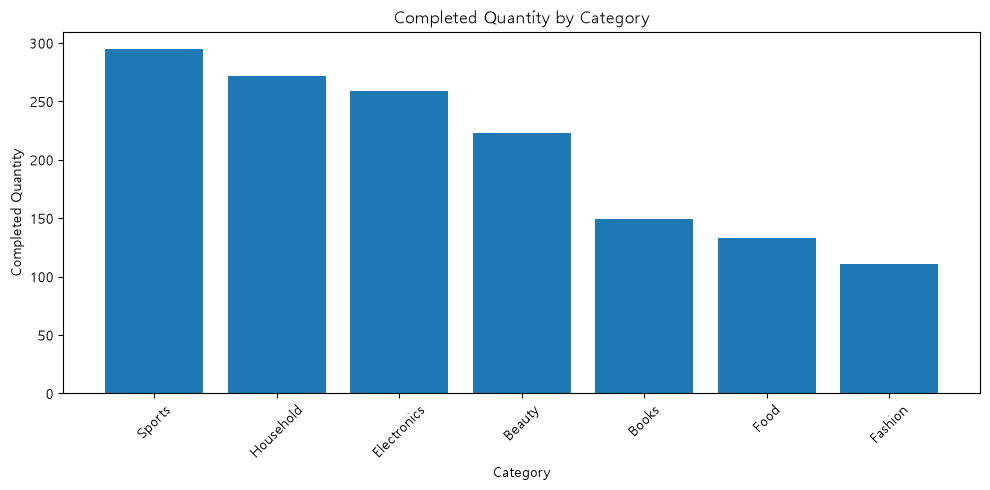

In [31]:
# 과제 1. 카테고리별 판매 수량 막대그래프를 추가로 그려 보세요.
# completed 주문으로 범위를 고정함
assignment_completed_orders = orders.loc[orders['order_status'].eq('completed'), ['order_id', 'order_date', 'customer_id']].copy()
assignment_completed_items = order_items.merge(assignment_completed_orders, on='order_id', how='inner')
assignment_completed_items['order_date'] = pd.to_datetime(assignment_completed_items['order_date'], errors='coerce')
assignment_completed_items = assignment_completed_items.merge(
    products[['product_id', 'category']], on='product_id', how='left'
)
assignment_category_quantity = (
    assignment_completed_items.groupby('category', as_index=False)
    .agg(completed_quantity=('quantity', 'sum'))
    .sort_values('completed_quantity', ascending=False)
)
assignment_category_quantity_total = assignment_category_quantity['completed_quantity'].sum()
assignment_source_quantity_total = assignment_completed_items['quantity'].sum()
print(assignment_category_quantity.to_csv(index=False))
print('category_quantity_total:', assignment_category_quantity_total)
print('completed_source_quantity_total:', assignment_source_quantity_total)
print('category_quantity_difference:', assignment_category_quantity_total - assignment_source_quantity_total)
print('category_missing_count:', assignment_completed_items['category'].isna().sum())

setup_korean_font('Malgun Gothic')
assignment_category_quantity['display_category'] = assignment_category_quantity['category'].map({'스포츠': 'Sports', '생활용품': 'Household', '전자기기': 'Electronics', '뷰티': 'Beauty', '도서': 'Books', '식품': 'Food', '패션': 'Fashion'}).fillna(assignment_category_quantity['category'])
plt.figure(figsize=(10, 5))
plt.bar(assignment_category_quantity['display_category'], assignment_category_quantity['completed_quantity'])
plt.title('Completed Quantity by Category')
plt.xlabel('Category')
plt.ylabel('Completed Quantity')
plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_assignment_category_quantity.png', dpi=150, bbox_inches='tight')
plt.show()

payment_method,order_count
kakao_pay,79
naver_pay,77
bank_transfer,74
card,70

payment_method_missing_count: 0
payment_count_total: 300
orders_row_total: 300
payment_count_difference: 0


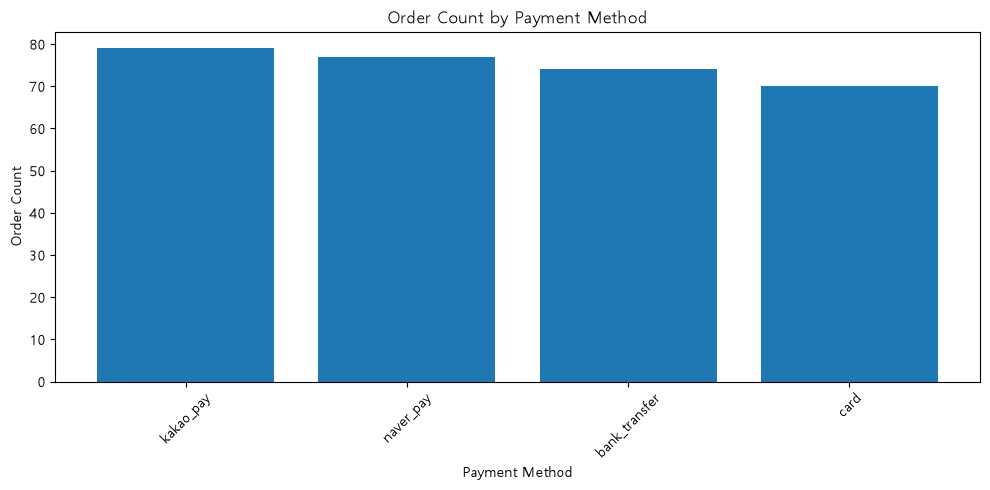

In [32]:
# 과제 2. 결제수단별 주문 수 막대그래프를 그려 보세요.
assignment_payment_counts = (
    orders['payment_method'].value_counts(dropna=False)
    .rename_axis('payment_method').reset_index(name='order_count')
)
assignment_payment_total = assignment_payment_counts['order_count'].sum()
print(assignment_payment_counts.to_csv(index=False))
print('payment_method_missing_count:', orders['payment_method'].isna().sum())
print('payment_count_total:', assignment_payment_total)
print('orders_row_total:', len(orders))
print('payment_count_difference:', assignment_payment_total - len(orders))

plt.figure(figsize=(10, 5))
plt.bar(assignment_payment_counts['payment_method'].fillna('missing').astype(str), assignment_payment_counts['order_count'])
plt.title('Order Count by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Order Count')
plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ch07_assignment_payment_method_count.png', dpi=150, bbox_inches='tight')
plt.show()


customer_count: 150
age_missing_count: 0
count    150.000000
mean      42.086667
std       15.613166
min       19.000000
25%       29.000000
50%       40.000000
75%       57.000000
max       69.000000


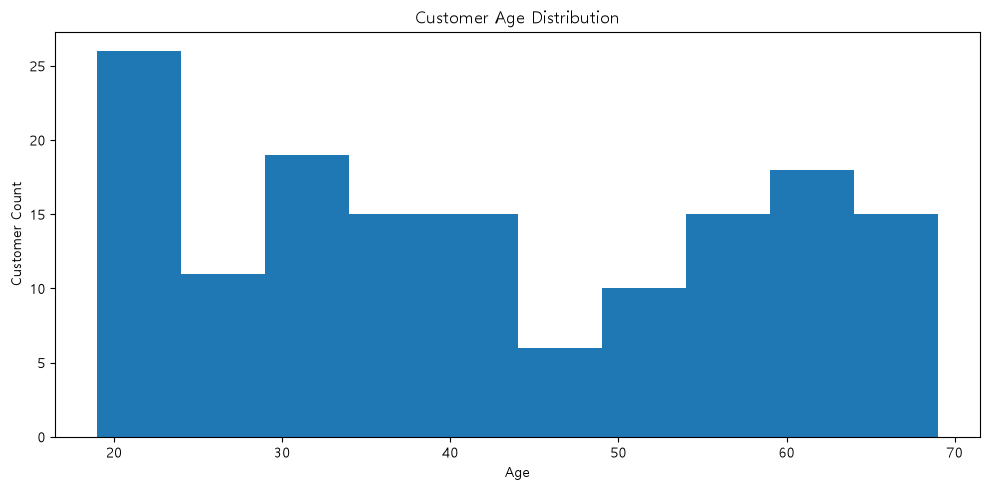

In [33]:
# 과제 3. 고객 나이 분포 히스토그램을 그려 보세요.
assignment_age = customers['age'].dropna()
print('customer_count:', len(customers))
print('age_missing_count:', customers['age'].isna().sum())
print(assignment_age.describe().to_string())

plt.figure(figsize=(10, 5))
plt.hist(assignment_age, bins=10)
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()


order_month,order_count
2025-07,8
2025-08,18
2025-09,13
2025-10,26
2025-11,12
2025-12,14
2026-01,22
2026-02,17
2026-03,14
2026-04,23
2026-05,11
2026-06,4
2026-07,2

monthly_completed_order_total: 184
completed_order_total: 184
monthly_order_difference: 0


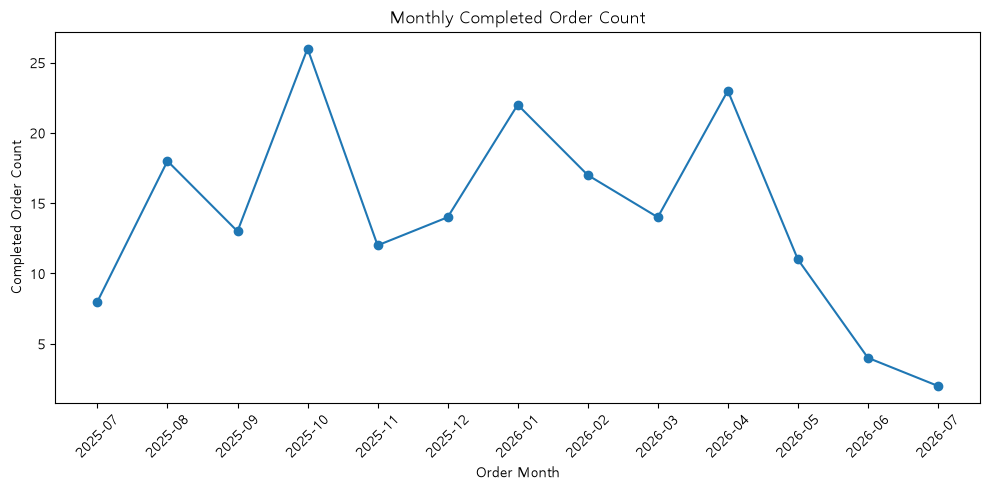

In [34]:
# 과제 4. 월별 주문 수 선 그래프를 그려 보세요.
# 완료 주문의 시간 흐름을 비교하기 위해 completed 주문만 사용한다.
assignment_monthly_order_count = (
    assignment_completed_orders.assign(
        order_date=lambda frame: pd.to_datetime(frame['order_date'], errors='coerce')
    )
    .dropna(subset=['order_date'])
    .assign(order_month=lambda frame: frame['order_date'].dt.to_period('M').astype(str))
    .groupby('order_month', as_index=False)
    .agg(order_count=('order_id', 'nunique'))
    .sort_values('order_month')
)
assignment_monthly_order_total = assignment_monthly_order_count['order_count'].sum()
print(assignment_monthly_order_count.to_csv(index=False))
print('monthly_completed_order_total:', assignment_monthly_order_total)
print('completed_order_total:', assignment_completed_orders['order_id'].nunique())
print('monthly_order_difference:', assignment_monthly_order_total - assignment_completed_orders['order_id'].nunique())

plt.figure(figsize=(10, 5))
plt.plot(assignment_monthly_order_count['order_month'], assignment_monthly_order_count['order_count'], marker='o')
plt.title('Monthly Completed Order Count')
plt.xlabel('Order Month')
plt.ylabel('Completed Order Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


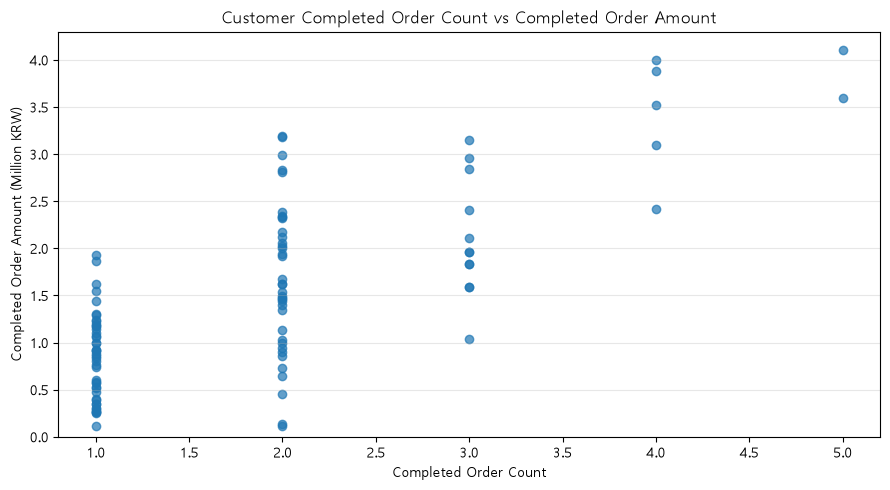

In [35]:
# 과제 5. 고객별 주문 횟수와 총 구매 금액의 관계를 산점도로 그려 보세요.
# customer_sales는 completed 주문 기준으로 집계했다.
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    customer_sales['order_count'],
    customer_sales['total_sales'],
    alpha=0.7,
)

ax.set_title('Customer Completed Order Count vs Completed Order Amount')
ax.set_xlabel('Completed Order Count')
ax.set_ylabel('Completed Order Amount (Million KRW)')
ax.set_ylim(bottom=0)

# y축 금액을 백만 원 단위로 표시
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f'{value / 1_000_000:,.1f}')
)

ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / 'ch07_customer_order_count_sales_scatter.png',
    dpi=150,
    bbox_inches='tight',
)

plt.show()

## 22. 정리

이번 장에서는 다음 내용을 실습했습니다.

- 분석 질문에 맞는 그래프 선택
- matplotlib 기본 구조와 한글 폰트 설정
- 시각화를 위한 집계 데이터 준비
- 카테고리별 매출 막대그래프
- 월별 매출 선 그래프
- 상품 가격 분포 히스토그램
- 상품 가격과 판매 수량 산점도
- 구매 금액 상위 고객 가로 막대그래프와 익명화
- 주문 상태별 주문 수 막대그래프
- 그래프 파일 저장과 시각화 요약 보고서 작성
- `src/visualization.py`와 `scripts/run_visualization.py`로 반복 실행 가능한 구조 만들기

다음 장에서는 지금까지 배운 데이터 불러오기, 전처리, EDA, 시각화를 종합하여 중간 실습 프로젝트를 수행합니다.


## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유
카테고리별 completed 주문 기준 금액 막대그래프가 가장 중요하다고 생각했다. 같은 completed 범위에서 카테고리별 금액 차이를 바로 비교할 수 있기 때문이다. completed source total(148,990,000원)과 카테고리별 합계가 일치하는지, 막대 높이가 집계표 값과 같은지도 확인했다. all status로 그렸을 때와 순위가 달라져(뷰티 2위 → 4위) 분석 범위를 고정하는 것이 왜 중요한지도 이 그래프가 가장 잘 보여 줬다.

### 그래프가 보여 준 사실
completed 주문 기준 금액이 큰 순서대로 스포츠, 전자기기, 생활용품, 뷰티, 식품, 도서, 패션 순이었다. 스포츠는 31,743,000원으로 가장 컸고 패션은 10,587,000원으로 가장 작았다. 두 카테고리의 차이는 21,156,000원이었고 스포츠는 패션의 약 3.0배였다. 반면 생활용품과 뷰티(차이 532,000원), 식품과 도서(차이 184,000원)는 금액 차이가 매우 작았다. 처음 그래프에서는 큰 숫자가 `1e7` 형식으로 표시되었는데 이후 y축을 백만 원 단위로 바꾸고 막대 위에 금액을 표시하도록 고쳤다.

### 그래프만으로 말할 수 없는 것
주문 금액이 크다고 고객 선호도나 수익성, 만족도도 높다고 볼 수는 없다. 총 주문 금액에는 판매 수량과 상품 단가가 함께 반영된다. 실제로 생활용품은 전자기기보다 판매 수량이 많지만 금액은 작았다. 판매량이 많아서 금액이 큰 것인지 상품 가격이 높아서 그런 것인지는 이 그래프만으로 알 수 없다. 취소/환불 주문은 제외했지만 원가, 할인, 배송비, 재고, 상품 수, 상품 노출 조건은 그래프에 포함되지 않았다. 실제 수익성이나 금액 차이의 원인을 알려면 다른 지표를 추가로 봐야 한다.

### 시각화에서 가장 주의해야 한다고 느낀 점
무엇보다 그래프에 사용한 데이터 범위를 고정하고 제목에 밝혀야 한다는 점을 느꼈다. 같은 카테고리 금액이라도 all status와 completed 중 무엇을 쓰느냐에 따라 순위와 월별 추세 해석이 달라졌다. 축의 범위와 단위도 잘 살펴야 한다. 축의 시작점을 다르게 잡으면 실제 차이보다 크거나 작게 보일 수 있는데 막대그래프는 막대 길이로 값을 비교하므로 y축을 0부터 시작하는 것이 특히 중요하다. 단위 표시도 빠뜨릴 수 없었다. 이번 그래프의 금액 단위는 원이지만 큰 숫자가 `1e7` 형식으로 표시되어 실제 금액을 바로 읽기 어려웠다. 그래서 축에 단위를 표시하고 숫자 형식도 확인할 필요가 있다. 히스토그램은 bins 설정에 따라서도 모양이 달라질 수 있다. 구간을 어떻게 나누느냐에 따라 특정 가격대가 많거나 적게 보일 수 있으므로, 한 가지 bins 설정만 보고 분포의 특징을 단정하면 안 된다.

### 다음 분석에서 확인할 질문
다음에는 카테고리별 판매 수량, 평균 판매 단가, 주문 수, 상품 수를 각각 비교한다. 스포츠의 높은 주문 금액이 어떤 지표와 함께 나타나는지 보기 위해서다. 판매 수량이 많은지, 평균 판매 단가가 높은지, 주문 수나 상품 수에서도 차이가 있는지 나누어 살펴볼 것이다. 카테고리별 취소/환불 비중도 비교한다. 2026년 6월에 completed 비중이 25.0%로 낮았던 이유는 주문 상태별 월별 건수로 확인할 것이다.

## 최종 체크
- [x] 금액 관련 그래프를 completed 주문 범위로 고정했습니다.
- [x] 그래프와 수치를 교차 검증했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.